# 3.3.4. Câu hỏi nghiên cứu Q5: Mức độ tập trung lượng người sở hữu theo thể loại game

### 1. Câu hỏi nghiên cứu

> **Trong mỗi thể loại game, nhóm 10% tựa game có lượng người sở hữu ước tính cao nhất chiếm bao nhiêu phần tổng lượng người sở hữu ước tính cộng gộp của thể loại đó? Mức độ tập trung này khác nhau thế nào giữa các thể loại lớn, và khác biệt có còn khi so sánh game cùng thời kỳ phát hành, cùng nhóm giá? Kết quả có vững khi thay ngưỡng top 10% bằng top 5% hoặc top 20% không?**

**Phạm vi câu hỏi:** đo sự tập trung của *ước tính ownership giữa các tựa game* trong từng thể loại. Không diễn giải tổng ownership cộng gộp thành số người chơi duy nhất: cùng một người có thể sở hữu nhiều game.

### 2. Động cơ và ý nghĩa thực tế

Hai thể loại có tổng ownership ước tính lớn có thể có cấu trúc rất khác nhau: một thể loại có thể dựa chủ yếu vào vài tựa nổi bật, trong khi thể loại khác có lượng sở hữu được chia đều hơn giữa nhiều tựa. Tỷ trọng ownership của nhóm game dẫn đầu giúp mô tả mức độ phụ thuộc vào các tựa đầu tàu trong mỗi phân khúc.

**Đối tượng hưởng lợi:** nhà phát hành, studio và nhóm nghiên cứu thị trường đang cân nhắc danh mục game theo thể loại. Nếu ownership tập trung cao, việc nhìn vào quy mô toàn thể loại có thể làm cơ hội của game điển hình trông lớn hơn thực tế. Đây là tín hiệu mô tả để đặt câu hỏi về rủi ro danh mục; không phải dự báo doanh thu, lợi nhuận hay tỷ lệ thành công.

### 3. Biến số và định nghĩa đo lường

| Biến | Vai trò |
|---|---|
| `appid` | Đơn vị phân tích; kiểm tra một dòng tương ứng một game. |
| `estimated_owners` | Dải ước tính ownership của game; tách cận dưới/cận trên và dùng trung điểm cho phân tích chính. |
| `genres` | Danh sách thể loại; dùng thể loại đầu tiên làm thể loại chính để mỗi game chỉ được tính một lần. |
| `release_date` | Tạo nhóm thời kỳ phát hành để so sánh các cohort game khác tuổi đời tích lũy. |
| `price` | Nhóm miễn phí theo giá (`price = 0`) và trả phí (`price > 0`) để kiểm soát khác biệt cơ cấu. |

Biến dẫn xuất chính:

\[
\text{Tỷ trọng top } p\% =
\frac{\sum \text{ownership midpoint của } p\% \text{ game cao nhất}}
{\sum \text{ownership midpoint của tất cả game trong nhóm}}
\]

Giá trị cao nghĩa là ownership ước tính tập trung hơn vào ít tựa game; không đồng nghĩa thị phần doanh thu hoặc số người chơi duy nhất.

### 4. Giả thuyết

- **H1:** Mức tập trung ownership khác nhau giữa các thể loại game.
- **H2:** Thể loại có khác biệt vẫn còn sau khi so sánh các nhóm game cùng thời kỳ phát hành và cùng nhóm giá.
- **H3:** Thứ tự/kết luận chính không đảo chiều khi dùng top 5%, top 10%, top 20%, hoặc cận dưới/cận trên thay trung điểm của `estimated_owners`.

### 5. Tiêu chí chiều sâu phân tích

| Tiêu chí | Thực hiện trong Q5 |
|---|---|
| **D2 — Reshaping & time** | Tạo các cohort theo thời kỳ phát hành và pivot tỷ trọng ownership theo thể loại × cohort. Đây là so sánh các nhóm game theo năm phát hành trong một snapshot, không phải chuỗi thời gian theo dõi cùng game. |
| **D3 — Derived variables** | Chuyển dải ownership thành cận dưới, cận trên, trung điểm; tính tỷ trọng ownership top 5%/10%/20%. |
| **D4 — Controlling for a confounder** | So sánh thể loại trong cùng cohort phát hành và cùng nhóm giá; chỉ dùng các tầng có đủ game ở mọi thể loại được đối chiếu. |
| **D5 — Quantifying uncertainty** | Bootstrap theo game trong từng tầng, báo khoảng tin cậy 95% cho tỷ trọng đã chuẩn hóa và chênh lệch giữa thể loại. |
| **D6 — Robustness check** | Thay ngưỡng top 5%/10%/20%; thay trung điểm bằng cận dưới/cận trên ownership; giữ rõ quy tắc ngưỡng mẫu. |

Q5 đáp ứng tối thiểu **D3, D4, D5, D6**; D2 là phân tích bổ sung theo cohort phát hành. Không thêm D1 chỉ để có merge: processed dataset đã chứa các cột cần thiết, và ghép thêm một bản sao của cùng dữ liệu không tạo thêm bằng chứng.

### 6. Giới hạn và khác biệt với các câu còn lại

Q1 nghiên cứu mối liên hệ giữa độ phủ nền tảng/ngôn ngữ và quy mô game; Q2/Q6 nghiên cứu thời lượng chơi; Q3 dự đoán hit game; Q4 tập trung DLC/achievement và review. Q5 không dự đoán một game có thành hit hay không, mà mô tả **ownership ước tính được phân bổ tập trung đến mức nào trong từng thể loại**.

`estimated_owners` là khoảng ước tính, không phải số đếm chính xác. Chọn thể loại đầu tiên bỏ qua thể loại phụ. Ownership là tích lũy, nên game cũ có thời gian tích lũy lâu hơn; cohort phát hành và giá giúp kiểm soát một phần cơ cấu nhưng không loại hết yếu tố gây nhiễu. Không thể suy ra quan hệ nhân quả, doanh thu hoặc lợi nhuận.

## 3.4.4. Phân tích câu hỏi nghiên cứu Q5: Mức độ tập trung ownership theo thể loại

### 1. Mục tiêu phân tích

Phân tích trả lời ba ý: (1) trong mỗi thể loại, bao nhiêu phần ownership ước tính cộng gộp thuộc về nhóm 10% game có ownership cao nhất; (2) sự khác biệt giữa các thể loại lớn có còn khi so sánh game cùng cohort phát hành và cùng nhóm giá; và (3) kết luận có đổi khi thay ngưỡng top 10% hoặc cách đại diện cho khoảng `estimated_owners` hay không.

Đơn vị phân tích là **một tựa game (`appid`)**. Ownership là lượng sở hữu ước tính tích lũy của tựa game trong snapshot tháng 03/2025, không phải số người chơi đang hoạt động hay số người duy nhất.

### 2. Chuẩn bị dữ liệu

Dữ liệu lấy từ `data/processed/steam_games_mar2025.csv`, gồm **89.618 dòng và 89.618 `appid` duy nhất**. Chỉ đọc năm cột cần thiết: `appid`, `estimated_owners`, `release_date`, `price`, `genres`. Không nối bảng khác vì các biến cần cho câu hỏi đã có trong cùng nguồn; không tạo phép ghép chỉ để thêm tiêu chí D1.

`estimated_owners` được công bố theo khoảng, ví dụ `20,000–50,000`. Phân tích chính dùng trung điểm khoảng. `genres` có thể chứa nhiều thể loại; lấy thể loại đầu tiên làm thể loại chính để mỗi game chỉ đóng góp một lần. Cohort phát hành là đến 2009, 2010–2014, 2015–2019, 2020–2022, 2023–2025. Giá tại snapshot được chia thành `Miễn phí` (`price = 0`) và `Trả phí` (`price > 0`); đây là phân loại theo giá quan sát, không khẳng định mô hình kinh doanh lâu dài.

### 3. Tiền xử lý dữ liệu

Các bước dưới đây được áp dụng tuần tự. Sau mỗi điều kiện lọc, mã in số dòng trước/sau và số bị loại; bảng ngay sau phần này lưu các con số đó để có thể kiểm tra mà không cần đọc mã. Thứ tự lọc quan trọng: mỗi số bị loại ở một bước là số dòng còn lại ngay trước bước đó.

1. Chuyển `price` sang số và giữ giá không âm; ngày phát hành được chuyển sang ngày tháng và phải hợp lệ, không muộn hơn 31/03/2025.
2. Tách cận dưới/cận trên ownership, tính trung điểm và chỉ giữ giá trị đọc được có trung điểm lớn hơn 0. Dòng thiếu, sai định dạng, khoảng không hợp lệ hoặc không có ownership dương không thể đóng góp hợp lệ vào tỷ trọng.
3. Đọc danh sách thể loại và giữ game xác định được thể loại chính. Mỗi game được gán đúng một thể loại để tránh đếm lặp.
4. Tạo năm/cohort phát hành và nhóm giá. Đây là tạo biến, không lọc thêm game; mã kiểm tra số dòng trước/sau vẫn bằng nhau và kiểm tra `appid` không trùng.

Không điền giá trị ownership thiếu bằng 0: 0 sẽ làm thay đổi mẫu số và có thể làm tỷ trọng tập trung sai lệch. Các phép chia cohort/nhóm giá và chọn tập so sánh được báo riêng ở phần phân tích, vì chúng chỉ giới hạn một phép so sánh chứ không thay thế tập dữ liệu nền.

In [1]:
from ast import literal_eval
import os
from pathlib import Path
import re
import sys

if os.name == 'nt':
    DLL_DIRECTORY_HANDLES = []
    for dll_directory in [
        Path(sys.prefix) / 'Library' / 'bin',
        Path(sys.prefix) / 'Library' / 'mingw64' / 'bin',
    ]:
        if dll_directory.is_dir():
            DLL_DIRECTORY_HANDLES.append(os.add_dll_directory(str(dll_directory)))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

DATA_CANDIDATES = [
    Path('data') / 'processed' / 'steam_games_mar2025.csv',
    Path('..') / 'data' / 'processed' / 'steam_games_mar2025.csv',
]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        'Không tìm thấy data/processed/steam_games_mar2025.csv từ thư mục hiện tại.'
    )

REQUIRED_COLUMNS = ['appid', 'estimated_owners', 'release_date', 'price', 'genres']
raw = pd.read_csv(DATA_PATH, usecols=REQUIRED_COLUMNS, low_memory=False)
missing_columns = sorted(set(REQUIRED_COLUMNS) - set(raw.columns))
if missing_columns:
    raise ValueError(f'Thiếu cột cần thiết cho Q5: {missing_columns}')
if raw['appid'].isna().any() or raw['appid'].duplicated().any():
    raise ValueError('appid thiếu hoặc trùng; cần xác minh đơn vị game trước khi phân tích.')

print(f'Nguồn: {DATA_PATH.resolve()}')
print(f'Dữ liệu đầu vào: {len(raw):,} dòng, {len(raw.columns)} cột.')
print(f'appid duy nhất: {raw["appid"].nunique():,}.')

Nguồn: D:\LT cho KHDL\Project -LT KHDL\data\processed\steam_games_mar2025.csv
Dữ liệu đầu vào: 89,618 dòng, 5 cột.
appid duy nhất: 89,618.


**Diễn giải kết quả nạp dữ liệu.** Nguồn là CSV processed trong repository; phân tích đọc 5 trường cần thiết và xác nhận `appid` duy nhất để mỗi dòng đại diện một game. Tập đầu vào có 89.618 game. Đây là tập ban đầu trước khi áp dụng các điều kiện lọc ở bước tiếp theo.

In [2]:
def parse_owner_interval(value):
    values = [
        int(item.replace(',', ''))
        for item in re.findall(r'\d[\d,]*', str(value))
    ]
    if len(values) >= 2:
        lower, upper = values[:2]
        if upper < lower:
            return np.nan, np.nan
        return float(lower), float(upper)
    if len(values) == 1:
        return float(values[0]), float(values[0])
    return np.nan, np.nan


def parse_primary_genre(value):
    try:
        parsed = literal_eval(value) if isinstance(value, str) else value
    except (ValueError, SyntaxError):
        return None
    if isinstance(parsed, (list, tuple)) and parsed:
        return str(parsed[0]).strip() or None
    return None


analysis = raw.copy()
analysis['price'] = pd.to_numeric(analysis['price'], errors='coerce')
analysis['release_date'] = pd.to_datetime(analysis['release_date'], errors='coerce')
owner_bounds = analysis['estimated_owners'].map(parse_owner_interval)
analysis[['owners_lower', 'owners_upper']] = pd.DataFrame(
    owner_bounds.tolist(), index=analysis.index
)
analysis['owners_midpoint'] = (analysis['owners_lower'] + analysis['owners_upper']) / 2
analysis['primary_genre'] = analysis['genres'].map(parse_primary_genre)

filter_log = []

def keep_rows(frame, label, mask):
    before = len(frame)
    filtered = frame.loc[mask].copy()
    after = len(filtered)
    filter_log.append({
        'Bước lọc': label,
        'Trước lọc': before,
        'Sau lọc': after,
        'Bị loại': before - after,
    })
    print(f'{label}: {before:,} -> {after:,}; loại {before - after:,} dòng.')
    return filtered


analysis = keep_rows(
    analysis,
    'Giá hợp lệ và không âm',
    analysis['price'].notna() & analysis['price'].ge(0),
)
analysis = keep_rows(
    analysis,
    'Ngày phát hành hợp lệ đến 31/03/2025',
    analysis['release_date'].notna()
    & analysis['release_date'].le(pd.Timestamp('2025-03-31')),
)
analysis = keep_rows(
    analysis,
    'Ownership đọc được, trung điểm lớn hơn 0',
    analysis['owners_midpoint'].notna() & analysis['owners_midpoint'].gt(0),
)
analysis = keep_rows(
    analysis,
    'Có thể xác định thể loại chính',
    analysis['primary_genre'].notna(),
)

analysis['release_year'] = analysis['release_date'].dt.year
analysis['release_period'] = pd.cut(
    analysis['release_year'],
    bins=[0, 2009, 2014, 2019, 2022, 2025],
    labels=['Đến 2009', '2010-2014', '2015-2019', '2020-2022', '2023-2025'],
    include_lowest=True,
)
analysis['price_group'] = np.where(analysis['price'].eq(0), 'Miễn phí', 'Trả phí')
assert analysis['release_period'].notna().all()
assert analysis['appid'].is_unique
print(f'Tạo biến dẫn xuất không đổi số dòng: {len(analysis):,} -> {len(analysis):,}.')
display(pd.DataFrame(filter_log).set_index('Bước lọc'))

Giá hợp lệ và không âm: 89,618 -> 89,618; loại 0 dòng.
Ngày phát hành hợp lệ đến 31/03/2025: 89,618 -> 89,618; loại 0 dòng.
Ownership đọc được, trung điểm lớn hơn 0: 89,618 -> 81,200; loại 8,418 dòng.
Có thể xác định thể loại chính: 81,200 -> 81,098; loại 102 dòng.
Tạo biến dẫn xuất không đổi số dòng: 81,098 -> 81,098.


,Trước lọc,Sau lọc,Bị loại
Bước lọc,,,
Giá hợp lệ và không âm,89618,89618,0
Ngày phát hành hợp lệ đến 31/03/2025,89618,89618,0
"Ownership đọc được, trung điểm lớn hơn 0",89618,81200,8418
Có thể xác định thể loại chính,81200,81098,102


**Diễn giải kết quả tiền xử lý.** Hai điều kiện về giá không âm và ngày phát hành đến 31/03/2025 không loại dòng nào. Có 8.418 dòng bị loại vì không có trung điểm ownership dương đọc được; sau đó loại thêm 102 dòng không xác định được thể loại chính. Tập phân tích cuối còn **81.098 game**, mỗi `appid` vẫn duy nhất. Việc tạo cohort và nhóm giá không làm thay đổi số dòng. Các số “trước/sau” là tuần tự, nên số bị loại ở mỗi bước được tính trên phần dữ liệu còn lại sau bước trước.

### 4. Phân tích khám phá

Trước khi so sánh có kiểm soát, tính trực tiếp tỷ trọng top 5%, top 10% và top 20% ở từng thể loại. Bước này cho thấy phân bố ownership ban đầu, nhưng **chưa** tách riêng khác biệt về thời kỳ phát hành hay cơ cấu giá. Chỉ đưa thể loại có ít nhất 100 game vào bảng/biểu đồ tổng quan để tránh nhấn mạnh các tỷ lệ rất bất ổn từ nhóm quá nhỏ; tập phân tích nền vẫn giữ toàn bộ game đủ điều kiện.

Bảng thứ hai ghi số game theo cohort × nhóm giá. Bảng này giúp người đọc thấy rõ vì sao phép so sánh có kiểm soát sau đó chỉ dùng các tầng mà cả bốn thể loại đều có đủ cỡ mẫu.

In [3]:
def concentration_share(values, fraction=0.10):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0 or values.sum() <= 0:
        return np.nan
    top_n = max(1, int(np.ceil(fraction * len(values))))
    return np.partition(values, len(values) - top_n)[-top_n:].sum() / values.sum()


BOOTSTRAP_RESAMPLES = 2000
BOOTSTRAP_BATCH_SIZE = 64
RANDOM_SEED = 42


def bootstrap_concentration(values, fractions=(0.05, 0.10, 0.20), n_resamples=BOOTSTRAP_RESAMPLES, rng=None):
    values = np.asarray(values, dtype=float)
    n = len(values)
    if n == 0 or values.sum() <= 0:
        raise ValueError('Không thể bootstrap concentration với mẫu rỗng hoặc tổng ownership <= 0.')
    rng = rng or np.random.default_rng(RANDOM_SEED)
    estimates = {fraction: np.empty(n_resamples, dtype=float) for fraction in fractions}
    for start in range(0, n_resamples, BOOTSTRAP_BATCH_SIZE):
        stop = min(start + BOOTSTRAP_BATCH_SIZE, n_resamples)
        sampled = np.sort(
            values[rng.integers(0, n, size=(stop - start, n))],
            axis=1,
        )
        totals = sampled.sum(axis=1)
        for fraction in fractions:
            top_n = max(1, int(np.ceil(fraction * n)))
            estimates[fraction][start:stop] = sampled[:, -top_n:].sum(axis=1) / totals
    return estimates


genre_counts_all = analysis.groupby('primary_genre', observed=True).size()
small_genre_mask = genre_counts_all < 100
small_genre_count = int(small_genre_mask.sum())
small_genre_game_count = int(genre_counts_all.loc[small_genre_mask].sum())
print(
    f'Tổng quan biểu đồ: {int((~small_genre_mask).sum())} thể loại, '
    f'{len(analysis) - small_genre_game_count:,} game; '
    f'không hiển thị {small_genre_count} thể loại nhỏ hơn 100 game '
    f'({small_genre_game_count:,} game). Tập phân tích nền không bị lọc thêm.'
)

genre_rows = []
rng_overall = np.random.default_rng(RANDOM_SEED)
for genre, group in analysis.groupby('primary_genre', observed=True):
    if len(group) < 100:
        continue
    values = group['owners_midpoint'].to_numpy()
    boot = bootstrap_concentration(values, fractions=(0.10,), rng=rng_overall)[0.10]
    genre_rows.append({
        'Thể loại': genre,
        'Số game': len(values),
        'Top 5%': concentration_share(values, 0.05),
        'Top 10%': concentration_share(values, 0.10),
        'Top 20%': concentration_share(values, 0.20),
        'CI dưới top 10%': np.quantile(boot, 0.025),
        'CI trên top 10%': np.quantile(boot, 0.975),
    })

genre_summary = pd.DataFrame(genre_rows).sort_values('Top 10%', ascending=False)
if genre_summary.empty:
    raise ValueError('Không có thể loại nào có ít nhất 100 game sau tiền xử lý.')
print(f'Thể loại đủ điều kiện trình bày (n >= 100): {len(genre_summary)}.')
display(genre_summary.style.format({
    'Top 5%': '{:.1%}',
    'Top 10%': '{:.1%}',
    'Top 20%': '{:.1%}',
    'CI dưới top 10%': '{:.1%}',
    'CI trên top 10%': '{:.1%}',
}))

cohort_counts = (
    analysis.groupby(['release_period', 'price_group'], observed=True)
    .size().rename('Số game').reset_index()
)
display(cohort_counts.pivot(
    index='release_period', columns='price_group', values='Số game'
).fillna(0).astype(int))

Tổng quan biểu đồ: 16 thể loại, 80,691 game; không hiển thị 11 thể loại nhỏ hơn 100 game (407 game). Tập phân tích nền không bị lọc thêm.


Thể loại đủ điều kiện trình bày (n >= 100): 16.


,Thể loại,Số game,Top 5%,Top 10%,Top 20%,CI dưới top 10%,CI trên top 10%
0,Action,33332,83.2%,90.1%,94.1%,88.5%,91.6%
13,Strategy,1102,73.0%,84.0%,91.2%,79.2%,87.5%
9,RPG,1368,71.1%,83.3%,92.0%,76.6%,87.9%
2,Animation & Modeling,278,76.1%,83.3%,87.6%,62.5%,91.2%
11,Simulation,1773,70.5%,82.7%,91.0%,78.8%,85.6%
3,Audio Production,116,74.6%,81.7%,85.2%,46.5%,91.5%
10,Racing,411,67.3%,81.2%,90.3%,72.2%,86.3%
8,Indie,7726,70.0%,79.2%,86.5%,75.4%,82.5%
1,Adventure,17127,66.0%,76.0%,84.5%,73.4%,78.3%
12,Sports,167,57.1%,75.5%,87.5%,65.7%,81.3%


price_group,Miễn phí,Trả phí
release_period,,
Đến 2009,7,89
2010-2014,232,2399
2015-2019,3866,22268
2020-2022,2318,21710
2023-2025,494,27715


**Cách đọc bảng mô tả.** Tập phân tích có 81.098 game; bảng hiển thị 80.691 game thuộc 16 thể loại có ít nhất 100 game. Còn 407 game thuộc 11 thể loại nhỏ hơn ngưỡng này nên không xuất hiện trong bảng. Action có top 10% chiếm **90,1%** trên 33.332 game; Education có **32,7%** trên 156 game. Top 5% và top 20% cho thấy mức tập trung tăng khi nhóm đầu được mở rộng, như định nghĩa chỉ số dự đoán. Bảng này là so sánh chưa điều chỉnh cơ cấu cohort/giá; các khoảng bootstrap của từng thể loại mô tả biến thiên lấy mẫu game chứ không phải sai số đo ownership.

### 5. Phân tích thống kê

#### 5.1. Đại lượng cần ước lượng

Đại lượng chính là **tỷ trọng ownership ước tính cộng gộp thuộc về nhóm game dẫn đầu**. Với một nhóm gồm \(N\) game, ký hiệu \(m_i\) là trung điểm khoảng `estimated_owners` của game \(i\). Sắp xếp \(m_i\) giảm dần, chọn \(k=\lceil pN\rceil\) game đầu bảng, rồi tính:

\[
C_p = \frac{\sum_{i \in \text{top } k} m_i}
{\sum_{i=1}^{N} m_i}, \qquad k=\lceil pN\rceil.
\]

Phân tích chính dùng \(p=0.10\); kiểm tra độ nhạy dùng \(p=0.05\) và \(p=0.20\). Làm tròn lên bảo đảm nhóm dẫn đầu có ít nhất một game. Chẳng hạn \(C_{0.10}=0.90\) có nghĩa là top 10% game chiếm 90% tổng trung điểm ownership của các game trong nhóm. Đây **không** phải 90% người chơi, vì một người có thể sở hữu nhiều tựa game và tổng số ước tính giữa các game có thể đếm trùng cùng người.

Chỉ số này phù hợp với câu hỏi về **mức độ tập trung giữa các tựa game**: nó so sánh đóng góp cộng gộp của phần đuôi dẫn đầu với toàn bộ nhóm. Chỉ số không đo quy mô tuyệt đối của thị trường; hai thể loại có cùng tỷ trọng vẫn có thể có tổng ownership rất khác nhau.

#### 5.2. Ước lượng mô tả và nhóm thể loại

Trước hết, \(C_p\) được tính riêng cho từng thể loại chính. Mỗi game chỉ thuộc thể loại đầu tiên trong danh sách `genres`, nhằm bảo toàn một dòng cho một đơn vị phân tích. Bảng mô tả trình bày top 5%, top 10%, top 20%, số game và khoảng tin cậy 95% cho top 10%. Thể loại có dưới 100 game không đưa vào bảng/biểu đồ tổng quan; ngưỡng này chỉ giới hạn phần trình bày, không xóa game khỏi tập dữ liệu nền.

#### 5.3. So sánh có điều kiện theo cohort và nhóm giá (D2, D4)

Ownership tích lũy theo thời gian nên tuổi đời game có thể làm thay đổi mức ownership quan sát được. Để hạn chế việc so sánh các nhóm có cơ cấu quá khác nhau, phân tích chọn bốn thể loại có nhiều game nhất (**Action, Adventure, Casual, Indie**) và tạo các tầng **cohort năm phát hành × nhóm giá**. Một tầng chỉ được đưa vào so sánh nếu cả bốn thể loại đều có ít nhất 30 game tại tầng đó. Có **7 tầng chung** đáp ứng tiêu chí. Trong các tầng này có 73.794 quan sát: 33.173 Action, 17.101 Adventure, 15.817 Casual và 7.703 Indie. Như vậy, 242 trong 74.036 game thuộc bốn thể loại lớn không nằm trong tầng chung và không đóng góp vào ước lượng chuẩn hóa.

Để tính tỷ trọng chuẩn hóa cho thể loại \(g\), trước tiên tính \(C_{0.10}\) riêng trong từng tầng \(s\), sau đó lấy trung bình cộng qua bảy tầng:

\[
\bar{C}_g = \frac{1}{7}\sum_{s=1}^{7} C_{g,s}.
\]

Mỗi tầng có trọng số như nhau, thay vì để tầng lớn nhất quyết định gần như toàn bộ kết quả. Vì vậy, \(̄C_g\) trả lời câu hỏi về mức tập trung trung bình trong các tầng chung, **không phải** tỷ trọng ownership gộp của toàn bộ Steam hay trung bình có trọng số theo số game.

#### 5.4. Định lượng độ bất định (D5)

Khoảng tin cậy được ước lượng bằng bootstrap phân vị với 2.000 lần lặp. Trong mỗi lần lặp, game được lấy mẫu lại có hoàn lại **bên trong từng tầng cohort × giá**, giữ nguyên cấu trúc tầng; sau đó tính lại tỷ trọng chuẩn hóa. Khoảng phân vị 2,5%–97,5% của 2.000 ước lượng tạo thành khoảng tin cậy bootstrap 95%. Với chênh lệch hai thể loại, mỗi lần lặp lấy hiệu giữa hai ước lượng đã chuẩn hóa, rồi lấy hai phân vị tương ứng.

Khoảng tin cậy mô tả bất định do lấy mẫu game theo quy trình này; nó không thể khắc phục sai số của bản thân `estimated_owners`. Phân tích tập trung vào độ lớn và khoảng bất định của tỷ trọng/chênh lệch thay vì kiểm định p-value. Ba so sánh Action với thể loại còn lại chưa được hiệu chỉnh cho việc thực hiện nhiều phép so sánh.

In [4]:
genre_counts = analysis.groupby('primary_genre', observed=True).size().sort_values(ascending=False)
major_genres = genre_counts.head(4).index.tolist()
print('Bốn thể loại được chọn theo số game:', ', '.join(major_genres))

stratum_rows = []
stratum_values = {}
for (genre, period, price_group), group in analysis.groupby(
    ['primary_genre', 'release_period', 'price_group'], observed=True
):
    if len(group) < 30:
        continue
    stratum = (str(period), price_group)
    values = group['owners_midpoint'].to_numpy()
    stratum_values[(genre, stratum)] = values
    stratum_rows.append({
        'Thể loại': genre,
        'Cohort phát hành': str(period),
        'Nhóm giá': price_group,
        'Số game': len(values),
        'Top 10% ownership': concentration_share(values, 0.10),
        'Top 5% ownership': concentration_share(values, 0.05),
        'Top 20% ownership': concentration_share(values, 0.20),
    })

stratum_table = pd.DataFrame(stratum_rows)
available_by_genre = {
    genre: set(
        map(tuple, stratum_table.loc[
            stratum_table['Thể loại'].eq(genre), ['Cohort phát hành', 'Nhóm giá']
        ].to_numpy())
    )
    for genre in major_genres
}
common_strata = sorted(
    set.intersection(*(available_by_genre[genre] for genre in major_genres)),
    key=lambda item: (
        ['Đến 2009', '2010-2014', '2015-2019', '2020-2022', '2023-2025'].index(item[0]),
        item[1],
    ),
)
if not common_strata:
    raise ValueError('Bốn thể loại lớn không có cohort × nhóm giá chung đủ 30 game.')

print(f'Tầng thể loại × cohort × giá đủ điều kiện: {len(stratum_table)}.')
print(f'Tầng chung dùng để đối chiếu bốn thể loại: {len(common_strata)}.')
major_genre_game_count = int(genre_counts.loc[major_genres].sum())
common_game_counts = {
    genre: sum(len(stratum_values[(genre, stratum)]) for stratum in common_strata)
    for genre in major_genres
}
common_sample_count = sum(common_game_counts.values())
print(
    f'Bốn thể loại lớn có {major_genre_game_count:,} game; '
    f'{common_sample_count:,} game nằm trong các tầng chung '
    f'({common_sample_count / len(analysis):.1%} của tập đã lọc). '
    f'Không thuộc tầng chung: {major_genre_game_count - common_sample_count:,} game.'
)
print('Số game trong tầng chung theo thể loại:', common_game_counts)
display(stratum_table.loc[
    stratum_table['Thể loại'].isin(major_genres)
    & stratum_table.set_index(['Thể loại', 'Cohort phát hành', 'Nhóm giá']).index.isin(
        [(genre, period, price) for genre in major_genres for period, price in common_strata]
    )
].sort_values(['Cohort phát hành', 'Nhóm giá', 'Thể loại']))

fractions = (0.05, 0.10, 0.20)
rng_adjusted = np.random.default_rng(RANDOM_SEED + 1)
bootstrap_by_genre = {
    genre: {fraction: np.zeros(BOOTSTRAP_RESAMPLES) for fraction in fractions}
    for genre in major_genres
}
point_by_genre = {genre: {fraction: 0.0 for fraction in fractions} for genre in major_genres}

for genre in major_genres:
    for stratum in common_strata:
        values = stratum_values[(genre, stratum)]
        boot = bootstrap_concentration(values, fractions=fractions, rng=rng_adjusted)
        for fraction in fractions:
            point_by_genre[genre][fraction] += (
                concentration_share(values, fraction) / len(common_strata)
            )
            bootstrap_by_genre[genre][fraction] += (
                boot[fraction] / len(common_strata)
            )

adjusted_rows = []
for genre in major_genres:
    boot = bootstrap_by_genre[genre][0.10]
    adjusted_rows.append({
        'Thể loại': genre,
        'Top 10% ownership đã chuẩn hóa': point_by_genre[genre][0.10],
        'CI dưới': np.quantile(boot, 0.025),
        'CI trên': np.quantile(boot, 0.975),
        'Số game trong tầng chung': sum(
            len(stratum_values[(genre, stratum)]) for stratum in common_strata
        ),
    })
adjusted_summary = pd.DataFrame(adjusted_rows).sort_values(
    'Top 10% ownership đã chuẩn hóa', ascending=False
)
display(adjusted_summary.style.format({
    'Top 10% ownership đã chuẩn hóa': '{:.1%}',
    'CI dưới': '{:.1%}',
    'CI trên': '{:.1%}',
}))

reference_genre = major_genres[0]
comparison_rows = []
for genre in major_genres[1:]:
    difference = (
        bootstrap_by_genre[reference_genre][0.10]
        - bootstrap_by_genre[genre][0.10]
    )
    point_difference = (
        point_by_genre[reference_genre][0.10]
        - point_by_genre[genre][0.10]
    )
    low, high = np.quantile(difference, [0.025, 0.975])
    comparison_rows.append({
        'So sánh': f'{reference_genre} - {genre}',
        'Chênh lệch (điểm %)': 100 * point_difference,
        'CI dưới (điểm %)': 100 * low,
        'CI trên (điểm %)': 100 * high,
    })
comparison_summary = pd.DataFrame(comparison_rows)
print('Chênh lệch chuẩn hóa; CI không điều chỉnh cho nhiều phép so sánh:')
display(comparison_summary.round(2))

Bốn thể loại được chọn theo số game: Action, Adventure, Casual, Indie
Tầng thể loại × cohort × giá đủ điều kiện: 73.
Tầng chung dùng để đối chiếu bốn thể loại: 7.
Bốn thể loại lớn có 74,036 game; 73,794 game nằm trong các tầng chung (91.0% của tập đã lọc). Không thuộc tầng chung: 242 game.
Số game trong tầng chung theo thể loại: {'Action': 33173, 'Adventure': 17101, 'Casual': 15817, 'Indie': 7703}


,Thể loại,Cohort phát hành,Nhóm giá,Số game,Top 10% ownership,Top 5% ownership,Top 20% ownership
2,Action,2010-2014,Trả phí,1015,0.664869,0.473284,0.817078
9,Adventure,2010-2014,Trả phí,516,0.622991,0.502531,0.757492
21,Casual,2010-2014,Trả phí,243,0.525456,0.411108,0.743262
35,Indie,2010-2014,Trả phí,241,0.713079,0.601272,0.812463
3,Action,2015-2019,Miễn phí,1465,0.905386,0.838850,0.956411
10,Adventure,2015-2019,Miễn phí,661,0.740492,0.637136,0.855928
22,Casual,2015-2019,Miễn phí,622,0.736982,0.611156,0.854401
36,Indie,2015-2019,Miễn phí,295,0.729477,0.574224,0.850702
4,Action,2015-2019,Trả phí,9460,0.855023,0.757416,0.921274
11,Adventure,2015-2019,Trả phí,4793,0.737086,0.610536,0.842445


,Thể loại,Top 10% ownership đã chuẩn hóa,CI dưới,CI trên,Số game trong tầng chung
0,Action,84.2%,81.5%,85.5%,33173
3,Indie,73.6%,66.5%,75.6%,7703
1,Adventure,69.0%,63.1%,72.2%,17101
2,Casual,65.5%,59.9%,68.1%,15817


Chênh lệch chuẩn hóa; CI không điều chỉnh cho nhiều phép so sánh:


,So sánh,Chênh lệch (điểm %),CI dưới (điểm %),CI trên (điểm %)
0,Action - Adventure,15.23,11.09,20.96
1,Action - Casual,18.74,14.91,24.11
2,Action - Indie,10.64,7.53,17.49


**Diễn giải phép so sánh có kiểm soát.** Bốn thể loại lớn có tổng cộng 74.036 game; trong đó **73.794 game (91,0% tập đã lọc)** thuộc 7 tầng cohort × nhóm giá chung và đóng góp vào so sánh chuẩn hóa. 242 game không thuộc tầng chung không bị xóa khỏi phân tích mô tả, chỉ không tham gia đại lượng so sánh này. Mỗi tầng được cho trọng số bằng nhau; vì vậy các ước lượng chuẩn hóa là mức trung bình giữa những tầng tương đồng, không phải tỷ trọng gộp toàn thị trường. Action đứng đầu với 84,2%; chênh lệch cặp với các thể loại khác được lượng hóa ở bảng ngay dưới.

### 6. Trực quan hóa

Các hình được xuất trực tiếp thành SVG tĩnh và nhúng trong notebook; vì vậy không cần cài renderer Plotly hoặc tải mã JavaScript từ Internet. Mỗi hình có tiêu đề, nhãn trục, đơn vị và chú giải; khoảng tin cậy được ghi rõ là bootstrap 95%.

#### Biểu đồ 1 — So sánh mô tả giữa các thể loại

Thanh thể hiện tỷ trọng ownership của top 10%; thanh sai số là KTC bootstrap 95%. Chỉ hiển thị thể loại có ít nhất 100 game. Đây là so sánh thô, chưa chuẩn hóa cohort phát hành và nhóm giá; dùng hình này để nhận diện khác biệt ban đầu, không thay thế kết quả có kiểm soát ở biểu đồ 2.

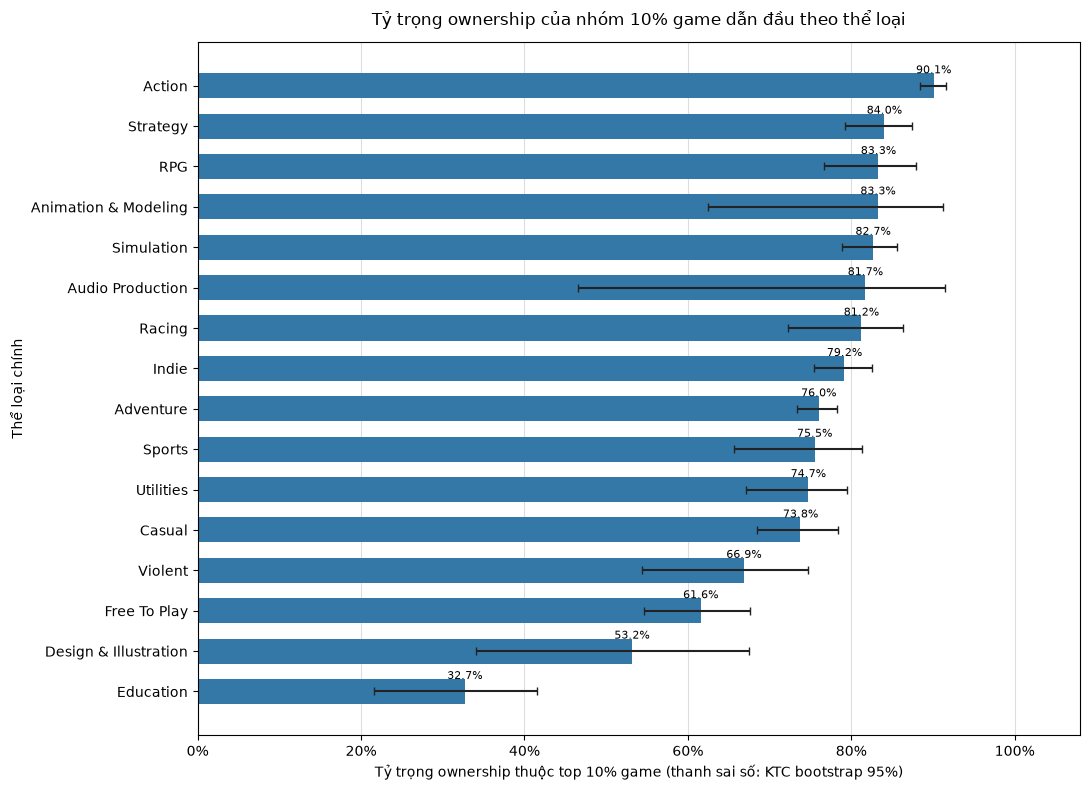

In [5]:
plot_data = genre_summary.sort_values('Top 10%', ascending=True).reset_index(drop=True)
positions = np.arange(len(plot_data))
point = plot_data['Top 10%'].to_numpy()
lower_error = point - plot_data['CI dưới top 10%'].to_numpy()
upper_error = plot_data['CI trên top 10%'].to_numpy() - point

fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(
    positions,
    point,
    xerr=np.vstack([lower_error, upper_error]),
    color='#3478a8',
    ecolor='#222222',
    capsize=3,
    height=0.62,
)
for y, estimate in zip(positions, point):
    ax.annotate(
        f'{estimate:.1%}', (estimate, y), xytext=(0, 7),
        textcoords='offset points', ha='center', va='bottom', fontsize=8,
    )

ax.set_yticks(positions, labels=plot_data['Thể loại'])
ax.set_xlim(0, 1.08)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel('Tỷ trọng ownership thuộc top 10% game (thanh sai số: KTC bootstrap 95%)')
ax.set_ylabel('Thể loại chính')
ax.set_title('Tỷ trọng ownership của nhóm 10% game dẫn đầu theo thể loại', pad=12)
ax.grid(axis='x', color='#dddddd')
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()
plt.close(fig)

**Diễn giải biểu đồ 1.** Action có tỷ trọng top 10% cao nhất trong so sánh thô; Education thấp nhất nhưng chỉ có 156 game. Hai đầu mút khác nhau 57,4 điểm phần trăm, song không nên xem toàn bộ khoảng cách là “hiệu ứng thể loại”: biểu đồ chưa chuẩn hóa cohort phát hành và nhóm giá. Thanh sai số biểu thị bootstrap 95%, không bao gồm sai số hệ thống của ước tính ownership.

#### Biểu đồ 2 — So sánh có kiểm soát giữa bốn thể loại lớn

Mỗi điểm là tỷ trọng top 10% sau khi lấy trung bình đều qua **cùng bảy** tầng cohort phát hành × nhóm giá. Thanh ngang là KTC bootstrap 95%. Dùng cùng các tầng giúp giảm khả năng chênh lệch chỉ phản ánh cơ cấu cohort hoặc giá khác nhau; đây vẫn là điều chỉnh cho hai biến quan sát được, không loại hết yếu tố gây nhiễu.

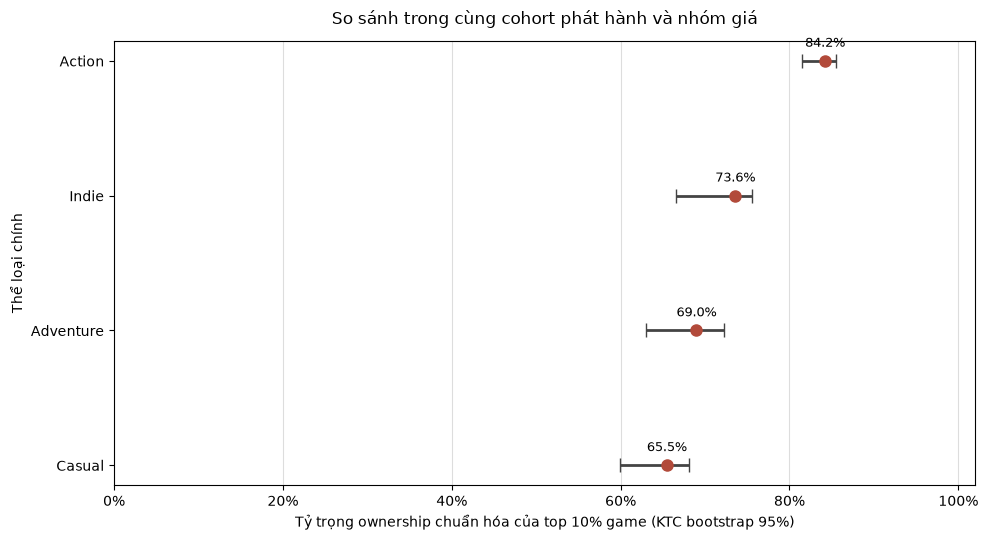

In [6]:
plot_data = adjusted_summary.sort_values(
    'Top 10% ownership đã chuẩn hóa', ascending=True
).reset_index(drop=True)
positions = np.arange(len(plot_data))
point = plot_data['Top 10% ownership đã chuẩn hóa'].to_numpy()
lower_error = point - plot_data['CI dưới'].to_numpy()
upper_error = plot_data['CI trên'].to_numpy() - point

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.errorbar(
    point, positions,
    xerr=np.vstack([lower_error, upper_error]),
    fmt='o', color='#b24a3a', ecolor='#444444', capsize=5,
    markersize=8, linewidth=2,
)
for y, estimate in zip(positions, point):
    ax.annotate(
        f'{estimate:.1%}', (estimate, y), xytext=(0, 8),
        textcoords='offset points', ha='center', va='bottom', fontsize=9,
    )

ax.set_yticks(positions, labels=plot_data['Thể loại'])
ax.set_xlim(0, 1.02)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel('Tỷ trọng ownership chuẩn hóa của top 10% game (KTC bootstrap 95%)')
ax.set_ylabel('Thể loại chính')
ax.set_title('So sánh trong cùng cohort phát hành và nhóm giá', pad=12)
ax.grid(axis='x', color='#dddddd')
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()
plt.close(fig)

**Diễn giải biểu đồ 2.** Sau khi chuẩn hóa trên cùng 7 tầng cohort × nhóm giá, Action vẫn cao hơn cả Adventure, Casual và Indie. Khoảng tin cậy của ước lượng điểm hỗ trợ độ bất định trong từng thể loại; bảng chênh lệch cặp định lượng trực tiếp khoảng cách giữa Action và từng nhóm. Hình này là bằng chứng chính cho so sánh có kiểm soát, nhưng chỉ điều chỉnh hai đặc điểm quan sát được và chưa hiệu chỉnh đa so sánh.

#### Biểu đồ 3 — Tỷ trọng top 10% theo cohort phát hành (D2)

Mỗi điểm tóm tắt các game thuộc thể loại/cohort đó; giá được gộp ở biểu đồ mô tả này. Chỉ hiện nhóm thể loại × cohort có ít nhất 30 game. Chú giải cho biết thể loại, còn bảng số game bên cạnh cho biết cỡ mẫu từng điểm. Cohort là nhóm game khác nhau ở một thời điểm chụp dữ liệu; không nối các điểm thành diễn biến của cùng các game qua thời gian.

Bảng cohort hiển thị 30 ô thể loại × cohort × giá đạt ngưỡng n >= 30; tổng cộng 73,947 game trong các ô đủ điều kiện.


Cohort phát hành,Đến 2009,2010-2014,2015-2019,2020-2022,2023-2025
Thể loại,,,,,
Action,0.626461,0.684957,0.861776,0.860973,0.856924
Adventure,—,0.622991,0.737499,0.703067,0.695558
Casual,—,0.525456,0.760710,0.623429,0.471590
Indie,—,0.713079,0.800722,0.708756,0.600013


Cohort phát hành,Đến 2009,2010-2014,2015-2019,2020-2022,2023-2025
Thể loại,,,,,
Action,34,1134,10925,9932,11301
Adventure,0,516,5454,5098,6033
Casual,0,243,4394,5047,6133
Indie,0,241,2524,2196,2742


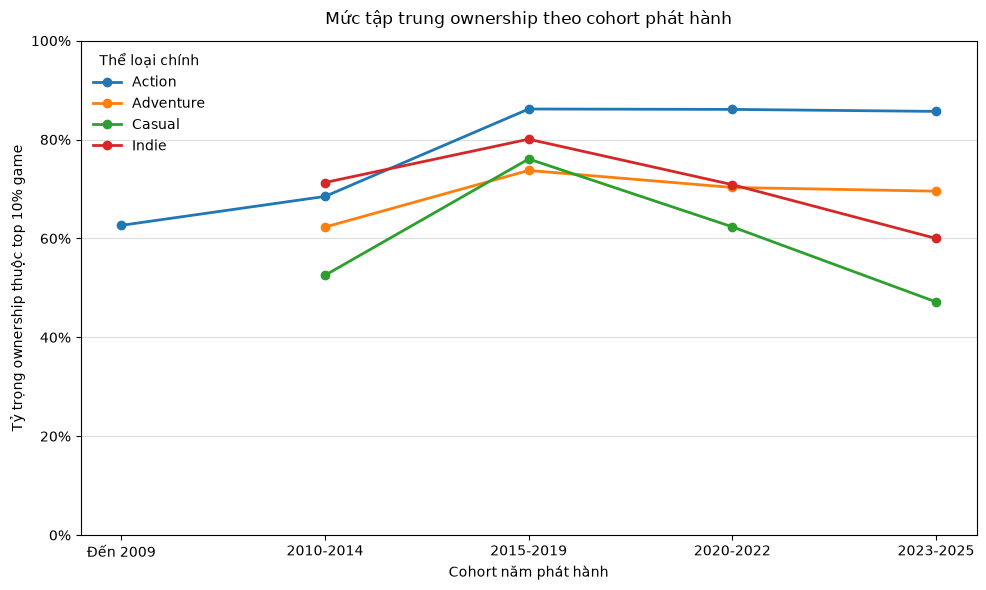

In [7]:
cohort_cells = stratum_table.loc[
    stratum_table['Thể loại'].isin(major_genres)
].copy()
print(
    f'Bảng cohort hiển thị {len(cohort_cells)} ô thể loại × cohort × giá '
    f'đạt ngưỡng n >= 30; tổng cộng {cohort_cells["Số game"].sum():,} game '
    'trong các ô đủ điều kiện.'
)
cohort_trend = (
    cohort_cells.groupby(['Thể loại', 'Cohort phát hành'], observed=True)
    .apply(lambda group: pd.Series({
        'Tỷ trọng top 10%': np.average(
            group['Top 10% ownership'], weights=group['Số game']
        ),
        'Số game': group['Số game'].sum(),
    }))
    .reset_index()
)
cohort_order = ['Đến 2009', '2010-2014', '2015-2019', '2020-2022', '2023-2025']
cohort_pivot = cohort_trend.pivot(
    index='Thể loại', columns='Cohort phát hành', values='Tỷ trọng top 10%'
).reindex(index=major_genres, columns=cohort_order)
display(cohort_pivot.style.format('{:.1%}').format(na_rep='—'))
display(cohort_trend.pivot(
    index='Thể loại', columns='Cohort phát hành', values='Số game'
).reindex(index=major_genres, columns=cohort_order).fillna(0).astype(int))

fig, ax = plt.subplots(figsize=(10, 6))
for genre in major_genres:
    ax.plot(
        cohort_order,
        cohort_pivot.loc[genre].to_numpy(dtype=float),
        marker='o',
        linewidth=2,
        markersize=6,
        label=genre,
    )

ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel('Cohort năm phát hành')
ax.set_ylabel('Tỷ trọng ownership thuộc top 10% game')
ax.set_title('Mức tập trung ownership theo cohort phát hành', pad=12)
ax.grid(axis='y', color='#dddddd')
ax.set_axisbelow(True)
ax.legend(title='Thể loại chính', frameon=False, loc='best')
fig.tight_layout()
plt.show()
plt.close(fig)

**Diễn giải biểu đồ 3.** Tỷ trọng top 10% của Action ở các cohort đủ điều kiện khoảng 86,2% trong 2015–2019 và 85,7% trong 2023–2025. Cùng hai cohort đó, Adventure khoảng 73,7% và 69,6%; Indie 80,1% và 60,0%; Casual 76,1% và 47,2%. Mức thay đổi giữa các cohort vì thế không đồng đều giữa thể loại. Đây là mô tả nhóm game khác nhau, không phải ownership của cùng game giảm theo thời gian; bảng số game đi kèm giúp nhận biết độ phủ mẫu cho từng cohort.

### 7. Kết quả và thảo luận

#### 7.1. Trả lời trực tiếp câu hỏi

Sau các bước tiền xử lý tuần tự, còn **81.098/89.618 game** (90,5% dữ liệu đầu vào). Trong 16 thể loại có ít nhất 100 game, ước lượng mô tả top 10% ownership thấp nhất ở **Education: 32,7% (n=156)** và cao nhất ở **Action: 90,1% (n=33.332)**. Khoảng cách thô là **57,4 điểm phần trăm**. Đây là so sánh chưa điều chỉnh; số Education có cỡ mẫu nhỏ hơn nhiều và cần được xem là mô tả, không nên xếp hạng chắc chắn các thể loại nhỏ dựa trên một ước lượng duy nhất.

Để trả lời liệu khác biệt có còn khi xét đến cơ cấu game, phép so sánh chính tập trung vào bốn thể loại lớn trong bảy tầng cohort phát hành × nhóm giá chung. Tỷ trọng top 10% chuẩn hóa và khoảng tin cậy bootstrap 95% là:

| Thể loại | Tỷ trọng top 10% chuẩn hóa | KTC bootstrap 95% | Game trong 7 tầng |
|---|---:|---:|---:|
| Action | **84,2%** | 81,5%–85,5% | 33.173 |
| Indie | **73,6%** | 66,5%–75,6% | 7.703 |
| Adventure | **69,0%** | 63,1%–72,2% | 17.101 |
| Casual | **65,5%** | 59,9%–68,1% | 15.817 |

Action vẫn có tỷ trọng tập trung cao nhất trong các tầng có cùng cohort và nhóm giá. So với Action, chênh lệch chuẩn hóa là **15,23 điểm phần trăm so với Adventure** (KTC 95%: 11,09–20,96), **18,74 điểm so với Casual** (14,91–24,11), và **10,64 điểm so với Indie** (7,53–17,49). Các khoảng bootstrap cho chênh lệch đều nằm trên 0; điều này hỗ trợ nhận định rằng mức tập trung của Action cao hơn trong phạm vi mẫu và phương pháp đã chọn. Tuy nhiên, vì chưa hiệu chỉnh đa so sánh, nên diễn giải đây là các ước lượng so sánh có điều kiện, không phải kết luận khẳng định cho mọi thể loại hay toàn bộ thị trường.

#### 7.2. Diễn giải theo cohort phát hành

Trong phần mô tả theo cohort, tỷ trọng top 10% giữa các thể loại không biến động đồng nhất. Với các ô đủ ít nhất 30 game, Action khoảng **86,2%** ở cohort 2015–2019 và **85,7%** ở 2023–2025; Adventure lần lượt khoảng **73,7%** và **69,6%**; Indie khoảng **80,1%** và **60,0%**; Casual khoảng **76,1%** và **47,2%**. Mức giảm giữa hai cohort nổi bật hơn ở Casual và Indie so với Action.

Đây là khác biệt giữa **các nhóm game phát hành ở thời kỳ khác nhau**, được quan sát trong cùng snapshot tháng 03/2025. Không thể kết luận rằng độ tập trung của cùng một thể loại đã giảm theo thời gian: các game của cohort mới có thời gian tích lũy ownership ngắn hơn, đồng thời thành phần game và điều kiện thị trường cũng khác. Vì biểu đồ cohort gộp hai nhóm giá theo số game của các ô đủ điều kiện, đây là mô tả bổ trợ; kết luận so sánh chính vẫn dựa trên chuẩn hóa với nhóm giá giữ riêng thành tầng.

#### 7.3. Insight chính và điểm đáng chú ý

**Insight 1 — Action nổi bật không chỉ vì quy mô mẫu lớn.** So sánh thô cho thấy top 10% game Action chiếm 90,1% tổng ownership ước tính của thể loại. Trong phép so sánh có kiểm soát, Action vẫn dẫn đầu với tỷ trọng chuẩn hóa 84,2%, cao hơn Adventure 15,23 điểm phần trăm, Casual 18,74 điểm và Indie 10,64 điểm. Cả ba khoảng tin cậy bootstrap 95% của chênh lệch đều nằm trên 0 (lần lượt 11,09–20,96; 14,91–24,11; 7,53–17,49 điểm phần trăm). Điểm đáng chú ý là khoảng cách không biến mất khi đối chiếu trong cùng cohort phát hành và nhóm giá; vì vậy, riêng khác biệt về hai đặc điểm này chưa giải thích hết mẫu hình quan sát được. Tuy nhiên, đây không phải bằng chứng rằng bản thân nhãn Action gây ra mức tập trung cao hơn: những yếu tố khác như thương hiệu, quy mô phát hành, thời lượng tồn tại, marketing và chất lượng game chưa được kiểm soát.

**Insight 2 — Trung bình của thị trường có thể bị kéo mạnh bởi nhóm dẫn đầu.** Tỷ trọng 84,2% của Action được chuẩn hóa bằng cách lấy trung bình ngang nhau tỷ trọng của bảy tầng cohort × nhóm giá chung; nó không phải tỷ lệ gộp tính trên toàn bộ 33.173 game của Action trong tập so sánh. Dù vậy, kết quả cho thấy trong từng cấu phần so sánh, phần ownership ước tính tập trung đáng kể vào nhóm game đứng đầu. Với người ra quyết định, điều này cảnh báo rằng số tổng của cả thể loại có thể tạo cảm giác về một thị trường rộng và đồng đều, trong khi kết quả thực tế của một tựa game riêng lẻ có thể khác xa các tựa dẫn đầu. Chỉ số này không cho biết “game điển hình” có bao nhiêu ownership; muốn trả lời cần xem thêm trung vị, phân vị và phân phối theo từng game.

**Insight 3 — Cohort mới không cho thấy một xu hướng giảm giống nhau ở mọi thể loại.** So sánh mô tả 2015–2019 với 2023–2025 cho thấy Action gần như ổn định (86,2% xuống 85,7%, chênh -0,5 điểm phần trăm), Adventure giảm khoảng 4,2 điểm (73,7% xuống 69,6%), trong khi Indie giảm khoảng 20,1 điểm (80,1% xuống 60,0%) và Casual giảm khoảng 28,9 điểm (76,1% xuống 47,2%). Sự khác nhau về độ lớn gợi ý rằng cấu trúc ownership của các thế hệ phát hành có thể không đồng nhất giữa thể loại. Đây là tín hiệu đáng để kiểm tra tiếp, không phải bằng chứng rằng game mới của Casual hay Indie sẽ kém thành công: cohort mới có ít thời gian tích lũy ownership hơn, các game trong mỗi cohort khác nhau về thành phần, và thống kê được tính tại một snapshot duy nhất.

**Insight 4 — Thứ hạng Action bền hơn độ lớn tuyệt đối.** Khi đổi định nghĩa nhóm dẫn đầu từ top 5% sang top 20%, Action lần lượt đạt 75,4%, 84,2% và 90,5% nhưng vẫn đứng đầu trong bốn thể loại. Khi dùng cận dưới/trung điểm/cận trên ownership, Action đạt 88,8%/84,2%/82,4% và vẫn giữ vị trí cao nhất. Ngược lại, khoảng dao động đáng kể cho thấy không nên xem 84,2% như một hằng số chính xác của thị trường: con số phụ thuộc vào ngưỡng nhóm dẫn đầu và cách biểu diễn khoảng ownership. Kết luận hợp lý hơn là thứ hạng tương đối của Action ổn định trong các kịch bản đã thử, còn độ lớn cần được báo cáo kèm định nghĩa và phân tích độ nhạy.

#### 7.4. Ý nghĩa thực tế theo nhóm đối tượng

**Studio độc lập hoặc nhóm phát triển nhỏ.** Kết quả không nói thể loại nào dễ thành công hơn, nhưng cho thấy không nên lấy những tựa dẫn đầu làm đại diện cho mức kết quả có thể kỳ vọng của cả phân khúc. Khi đánh giá cơ hội, studio có thể dùng tỷ trọng tập trung như một chỉ báo sàng lọc để đặt câu hỏi tiếp: phần lớn ownership có nằm ở vài thương hiệu lâu đời không; có nhóm game quy mô vừa đủ lớn để tạo chuẩn so sánh thực tế không; và một sản phẩm mới cần khác biệt ở đâu để không chỉ cạnh tranh trực tiếp với các tựa dẫn đầu? Trước khi quyết định sản xuất, cần bổ sung phân phối ownership, thời gian phát hành, đánh giá người dùng, mức cập nhật, chi phí tiếp thị và dữ liệu doanh thu/hoạt động.

**Nhà phát hành và nhóm nghiên cứu thị trường.** Khi lập báo cáo quy mô thể loại, nên trình bày đồng thời tổng ownership, số lượng game, tỷ trọng của nhóm đầu và các phân vị của phân phối. Cách trình bày này giúp phân biệt một phân khúc có nhiều tựa cùng đóng góp với một phân khúc có tổng lớn nhưng tập trung vào số ít tựa. Kết quả cohort cũng gợi ý nên phân tầng theo năm phát hành thay vì gộp game cũ và mới: ownership tích lũy chịu ảnh hưởng của thời gian hiện diện. Có thể dùng phát hiện để xác định nơi cần phân tích sâu hơn, nhưng không nên dùng nó một mình để dự báo doanh thu, xác suất thành công hay phân bổ ngân sách.

**Nhà nghiên cứu hoặc người xây dựng chính sách nền tảng.** Chênh lệch giữa các thể loại sau khi chuẩn hóa là căn cứ mô tả để khảo sát thêm tính không đồng đều của phân phối ownership. Để đánh giá cạnh tranh hoặc mức độ phụ thuộc vào một vài tựa game, cần có thêm thước đo như đường cong Lorenz/Gini, CR5/CR10 được tính trên cùng đơn vị, và dữ liệu theo thời gian. Dataset hiện tại không cho phép suy ra hành vi đề xuất của nền tảng, quyền lực thị trường hay tác động của chính sách; các khái niệm đó cần biến đo lường và thiết kế nghiên cứu riêng.

#### 7.5. Đối chiếu giả thuyết và phạm vi kết luận

- **H1 — Mức tập trung khác nhau theo thể loại:** được hỗ trợ về mặt mô tả; đặc biệt, Action cao hơn ba thể loại đối chiếu trong phép chuẩn hóa đã thực hiện. Không nên khái quát kết quả của bốn thể loại lớn thành kết luận cho mọi thể loại.
- **H2 — Khác biệt còn sau khi so sánh các nhóm tương đồng:** được hỗ trợ trong bảy tầng cohort phát hành × nhóm giá chung. Đây là kiểm soát có giới hạn, không loại trừ các yếu tố gây nhiễu chưa quan sát.
- **H3 — Kết luận bền với lựa chọn phân tích:** thứ hạng Action cao nhất giữ nguyên khi thay ngưỡng top 5%/10%/20% và khi dùng cận dưới/trung điểm/cận trên. Độ lớn thay đổi đáng kể, nên cần phân biệt độ bền về thứ hạng với độ chính xác của một con số cụ thể.

**Phạm vi diễn giải:** kết quả đo mức tập trung của tổng ownership ước tính giữa các tựa game trong snapshot. Nó không phải số người chơi duy nhất, người đang hoạt động, retention, CCU, doanh thu, lợi nhuận hay khả năng thành công của một game mới. Các chênh lệch là liên hệ mô tả, không chứng minh quan hệ nhân quả.

### 8. Kiểm tra độ bền vững (D6)

Độ bền vững được đánh giá bằng cách giữ nguyên bốn thể loại và bảy tầng cohort × nhóm giá chung, chỉ thay đổi một lựa chọn phân tích tại mỗi lần kiểm tra:

1. **Thay ngưỡng nhóm dẫn đầu:** so sánh top 5%, top 10% và top 20% theo trung điểm ownership.
2. **Thay đại diện cho khoảng ownership:** tính lại top 10% bằng cận dưới, trung điểm và cận trên của `estimated_owners`.

Các kịch bản cận dưới/cận trên là kiểm tra độ nhạy trước khoảng đo lường trong dữ liệu nguồn; chúng không phải khoảng tin cậy. Phân tích kiểm tra liệu thứ hạng tương đối có giữ nguyên, đồng thời ghi nhận độ lớn của tỷ trọng có phụ thuộc vào định nghĩa hay không.

,Thể loại,Top 5%,Top 10%,Top 20%
0,Action,75.4%,84.2%,90.5%
1,Adventure,58.6%,69.0%,79.7%
2,Casual,56.6%,65.5%,75.2%
3,Indie,62.4%,73.6%,82.1%


,Thể loại,Cận dưới,Trung điểm,Cận trên
0,Action,88.8%,84.2%,82.4%
1,Adventure,78.6%,69.0%,65.7%
2,Casual,83.8%,65.5%,60.9%
3,Indie,84.5%,73.6%,70.0%


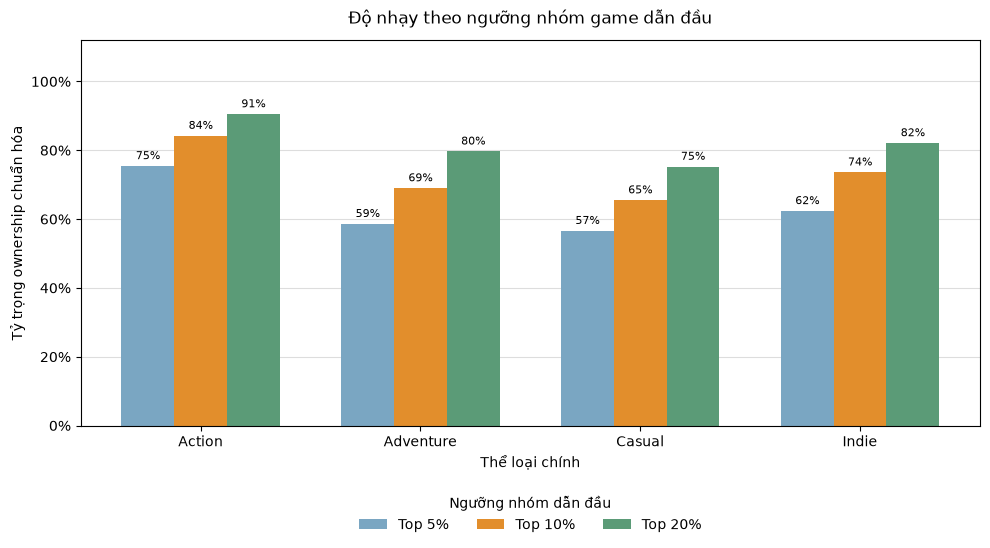

In [8]:
sensitivity_rows = []
for genre in major_genres:
    row = {'Thể loại': genre}
    for fraction in fractions:
        row[f'Top {int(fraction * 100)}%'] = point_by_genre[genre][fraction]
    sensitivity_rows.append(row)
sensitivity_fraction = pd.DataFrame(sensitivity_rows)
display(sensitivity_fraction.style.format({
    'Top 5%': '{:.1%}',
    'Top 10%': '{:.1%}',
    'Top 20%': '{:.1%}',
}))

endpoint_rows = []
for genre in major_genres:
    row = {'Thể loại': genre}
    for bound in ['owners_lower', 'owners_midpoint', 'owners_upper']:
        stratum_estimates = []
        for period, price_group in common_strata:
            group = analysis.loc[
                analysis['primary_genre'].eq(genre)
                & analysis['release_period'].astype(str).eq(period)
                & analysis['price_group'].eq(price_group),
                bound,
            ].to_numpy()
            stratum_estimates.append(concentration_share(group, 0.10))
        row[bound] = float(np.mean(stratum_estimates))
    endpoint_rows.append(row)
endpoint_sensitivity = pd.DataFrame(endpoint_rows).rename(columns={
    'owners_lower': 'Cận dưới',
    'owners_midpoint': 'Trung điểm',
    'owners_upper': 'Cận trên',
})
display(endpoint_sensitivity.style.format({
    'Cận dưới': '{:.1%}',
    'Trung điểm': '{:.1%}',
    'Cận trên': '{:.1%}',
}))

fig, ax = plt.subplots(figsize=(10, 6))
bar_width = 0.24
positions = np.arange(len(major_genres))
colors = ['#7aa6c2', '#e28e2c', '#5b9b77']
for index, fraction in enumerate(fractions):
    values = [point_by_genre[genre][fraction] for genre in major_genres]
    bars = ax.bar(
        positions + (index - 1) * bar_width,
        values,
        width=bar_width,
        color=colors[index],
        label=f'Top {int(fraction * 100)}%',
    )
    ax.bar_label(bars, labels=[f'{value:.0%}' for value in values], padding=3, fontsize=8)

ax.set_xticks(positions, labels=major_genres)
ax.set_ylim(0, 1.12)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel('Thể loại chính')
ax.set_ylabel('Tỷ trọng ownership chuẩn hóa')
ax.set_title('Độ nhạy theo ngưỡng nhóm game dẫn đầu', pad=12)
ax.grid(axis='y', color='#dddddd')
ax.set_axisbelow(True)
ax.legend(
    title='Ngưỡng nhóm dẫn đầu', frameon=False, ncol=3,
    loc='upper center', bbox_to_anchor=(0.5, -0.15),
)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()
plt.close(fig)

**Diễn giải kiểm tra độ bền vững.** Action vẫn có tỷ trọng chuẩn hóa cao nhất ở cả ba ngưỡng: **75,4% (top 5%)**, **84,2% (top 10%)**, **90,5% (top 20%)**. Khi thay trung điểm bằng cận dưới/cận trên, Action lần lượt là **88,8%**, **84,2%**, **82,4%** và vẫn đứng đầu. Thứ hạng dẫn đầu của Action do đó bền với các lựa chọn đã thử; độ lớn tuyệt đối thay đổi, và vị trí giữa Adventure/Casual/Indie nhạy hơn. Cận ownership là kịch bản độ nhạy, không phải khoảng tin cậy.

### 9. Giới hạn phân tích

1. **Ownership là khoảng ước tính, không phải số đếm chính xác.** Trung điểm là một quy ước đại diện cho khoảng; kết quả theo cận dưới và cận trên khác đáng kể về độ lớn. Bootstrap lượng hóa biến thiên lấy mẫu game có điều kiện trên các giá trị đã quan sát, không bao hàm sai số hệ thống hay bất định do cách Steam ước lượng ownership.
2. **Không suy ra quy mô người dùng duy nhất hoặc hoạt động hiện tại.** Một người có thể sở hữu nhiều game; cộng ownership qua các tựa có thể đếm lặp người. Snapshot ownership tích lũy không đo người đang chơi, CCU, retention hay mức hài lòng.
3. **Quy tắc thể loại chính làm đơn giản hóa game đa thể loại.** Mỗi game chỉ được xếp vào nhãn đầu tiên trong danh sách. Kết quả vì vậy phụ thuộc một phần vào thứ tự nhãn và không mô tả đầy đủ các thể loại phụ.
4. **Cohort không phải dữ liệu bảng theo dõi thời gian.** Các cohort gồm những game khác nhau và được quan sát tại một snapshot tháng 03/2025. Game cũ có nhiều thời gian tích lũy ownership hơn; nhóm 2023–2025 có thời gian quan sát ngắn và năm 2025 chưa trọn vẹn. Không thể diễn giải chênh lệch cohort như biến động của cùng một game.
5. **Kiểm soát yếu tố gây nhiễu còn hạn chế.** So sánh chuẩn hóa giữ cố định cohort phát hành và nhóm giá, nhưng chưa điều chỉnh đồng thời cho nhà phát hành, marketing, chất lượng, cập nhật, nền tảng, giảm giá, thời điểm ra mắt hoặc những khác biệt khác. `price = 0` chỉ mô tả giá tại snapshot, không đủ để xác định toàn bộ mô hình kinh doanh.
6. **Phạm vi so sánh có điều kiện.** Phân tích chuẩn hóa chỉ xét bốn thể loại lớn và bảy tầng chung có ít nhất 30 game của mỗi thể loại; 242 game thuộc bốn thể loại này nằm ngoài các tầng chung. Kết quả không đại diện tự động cho thể loại nhỏ hoặc toàn bộ danh mục Steam. Ngưỡng 100 game cho bảng tổng quan cũng là quy tắc trình bày, không phải ngưỡng suy luận phổ quát.
7. **Bất định bootstrap phụ thuộc giả định lấy mẫu.** Bootstrap lấy game làm đơn vị và coi các game trong tầng là có thể lấy mẫu lại độc lập. Tựa game có thể liên hệ qua cùng nhà phát hành, thương hiệu hoặc chuỗi game; sự phụ thuộc này không được mô hình hóa và có thể khiến khoảng tin cậy hẹp hơn độ bất định thực tế.
8. **Các so sánh nhiều cặp chưa hiệu chỉnh đa kiểm định.** Ba khoảng tin cậy của Action so với các thể loại khác cần được xem trong bối cảnh nhiều phép so sánh; chúng không thay thế một thiết kế kiểm định xác nhận có điều chỉnh.
9. **Không có suy luận nhân quả.** Mối liên hệ quan sát được không chứng minh thể loại, cohort hay giá gây ra mức tập trung; cũng không đủ để dự báo kết quả của game mới hoặc xác định xác suất sinh lời.

### 10. Kết luận

**Trả lời câu hỏi:** tỷ trọng ownership ước tính cộng gộp thuộc về nhóm 10% game dẫn đầu khác nhau giữa các thể loại. Trong so sánh chuẩn hóa trên cùng bảy tầng cohort phát hành × nhóm giá, ước lượng là **84,2% ở Action**, **73,6% ở Indie**, **69,0% ở Adventure** và **65,5% ở Casual**. Chênh lệch của Action so với Adventure, Casual và Indie lần lượt là **15,23**, **18,74** và **10,64 điểm phần trăm**; các khoảng tin cậy bootstrap 95% cho các chênh lệch này đều nằm trên 0 trong phân tích chưa hiệu chỉnh đa so sánh.

Thứ hạng Action cao nhất không đổi khi kiểm tra top 5%/10%/20% và khi dùng cận dưới hoặc cận trên của khoảng ownership. Do đó, kết quả ủng hộ kết luận rằng ownership ước tính trong các game Action quan sát được tập trung vào nhóm tựa dẫn đầu hơn so với ba thể loại lớn được đối chiếu. Kết luận này chỉ áp dụng trong phạm vi mẫu, định nghĩa ownership, cohort/nhóm giá và quy tắc chọn mẫu đã nêu; không đồng nghĩa Action có tổng ownership lớn nhất, cũng không chứng minh thể loại Action gây ra mức tập trung.

Về ứng dụng, khi đánh giá một phân khúc game, nên báo cáo **cả quy mô ownership cộng gộp lẫn cách ownership phân bố giữa các tựa**, đồng thời nêu cỡ mẫu và độ bất định. Chỉ số tập trung có thể hỗ trợ phân tích danh mục và đặt giả thuyết về sự phụ thuộc vào các tựa dẫn đầu; nó không phải thước đo số người chơi duy nhất, doanh thu, lợi nhuận hay xác suất thành công của game mới.

# 3.3.5. Câu hỏi nghiên cứu Q6: Thời lượng hoàn thành, tỷ lệ tiêu thụ nội dung và đánh giá người dùng

### 1. Câu hỏi nghiên cứu

> **Trong các game PC ghép được giữa snapshot Steam tháng 03/2025 và dữ liệu HowLongToBeat (HLTB), thời lượng hoàn thành do cộng đồng báo cáo liên hệ như thế nào với quy mô người sở hữu và tỷ lệ tiêu thụ nội dung thực tế trên Steam? Mức độ kéo dài nội dung có đi cùng tỷ lệ đánh giá tích cực cao hơn sau khi kiểm soát thể loại, tuổi game, giá bán và quy mô phản hồi không?**

**Phạm vi câu hỏi:** phân tích đo lường mối liên hệ ở cấp độ tựa game giữa thời lượng hoàn thành nội dung do cộng đồng ghi nhận với hành vi chơi thực tế và đánh giá tích cực của người dùng Steam. Không diễn giải các liên hệ quan sát được thành tác động nhân quả, và không xem việc kéo dài nội dung là khuyến nghị tự động để tăng doanh thu.

### 2. Động cơ và ý nghĩa thực tế

Trong ngành công nghiệp game, các nhà phát triển thường đứng trước bài toán đánh đổi về quy mô nội dung. Một mặt, thời lượng chơi dài thường được dùng làm luận điểm tiếp thị để định giá bán cao hơn và thu hút người mua. Mặt khác, việc kéo dài nội dung có thể dẫn đến hiện tượng loãng nhịp độ chơi, khiến phần lớn người dùng bỏ dở giữa chừng hoặc tạo ra phản ứng tiêu cực trong đánh giá.

**Đối tượng hưởng lợi:**
- **Studio độc lập và nhóm phát triển nhỏ:** hiểu rõ ngưỡng thời lượng tối ưu theo từng thể loại, tránh lãng phí nguồn lực sản xuất vào phần nội dung mà đa số người chơi không bao giờ trải nghiệm.
- **Nhà phát hành và nhóm nghiên cứu thị trường:** có căn cứ thực nghiệm để đánh giá mối liên hệ giữa thời lượng, định giá và quy mô người sở hữu, phân biệt giữa kỳ vọng tiếp thị ban đầu và mức độ hài lòng thực tế của cộng đồng.
- **Nhà nghiên cứu sản phẩm:** bổ sung bằng chứng định lượng về khoảng cách giữa thời lượng cam kết và thời gian chơi thực tế trên các nền tảng phân phối số.

### 3. Biến số và định nghĩa đo lường

| Biến | Nguồn | Vai trò trong phân tích |
|---|---|---|
| `appid` | Steam | Đơn vị phân tích cấp tựa game, đảm bảo mỗi dòng tương ứng một game duy nhất. |
| `name` | Steam / HLTB | Chuẩn hóa để ghép nối chính xác một-một giữa hai nguồn dữ liệu. |
| `main_story` | HLTB | Thời lượng trung vị hoàn thành cốt truyện chính do cộng đồng báo cáo (giờ). |
| `main_plus_sides` | HLTB | Thời lượng trung vị hoàn thành cốt truyện kèm nhiệm vụ phụ (giờ). |
| `completionist` | HLTB | Thời lượng trung vị hoàn thành toàn diện 100% nội dung (giờ). |
| `median_playtime_forever` | Steam | Thời gian chơi trung vị tích lũy trên Steam, quy đổi sang giờ. |
| `estimated_owners` | Steam | Khoảng ước tính lượng người sở hữu, dùng trung điểm cho phân tích chính. |
| `pct_pos_total` | Steam | Tỷ lệ đánh giá tích cực tổng thể của tựa game (%). |
| `price` | Steam | Giá niêm yết của tựa game (USD), kiểm soát biến gây nhiễu về định giá. |
| `release_date` | Steam | Tính tuổi đời phát hành của game tính đến năm 2025. |
| `genres` | Steam | Thể loại chính của game, phân tích tương tác và kiểm soát khác biệt cấu trúc. |

Biến dẫn xuất chính:

\[
\text{Tỷ số tiêu thụ nội dung} = \frac{\text{Steam median lifetime playtime (giờ)}}{\text{HLTB duration (giờ)}}
\]

\[
\text{Tỷ số phình nội dung phụ} = \frac{\text{Completionist duration (giờ)}}{\text{Main story duration (giờ)}}
\]

Tỷ số tiêu thụ nội dung lớn hơn hoặc bằng 1,0 thể hiện thời lượng chơi trung vị của người dùng Steam đạt hoặc vượt mốc thời lượng hoàn thành do cộng đồng HLTB ghi nhận.

### 4. Giả thuyết

- **H1:** Thời lượng hoàn thành dài hơn liên hệ dương với quy mô người sở hữu ước tính, nhưng mức độ liên hệ có sự phân hóa đáng kể theo từng thể loại game.
- **H2:** Tồn tại sự suy giảm phi tuyến tính rõ rệt trong tỷ số tiêu thụ nội dung khi thời lượng game tăng dần, thể hiện qua việc người chơi hoàn thành phần lớn game ngắn nhưng chỉ chơi một phần nhỏ game dài.
- **H3:** Sau khi kiểm soát giá bán, thể loại, tuổi game và quy mô đánh giá, thời lượng cốt truyện dài hơn không làm tăng tỷ lệ đánh giá tích cực, thậm chí ghi nhận hệ số âm có ý nghĩa thống kê trong thể loại Action.

### 5. Tiêu chí chiều sâu phân tích

| Tiêu chí | Thực hiện trong Q6 |
|---|---|
| **D1 — Tích hợp dữ liệu ngoài** | Ghép snapshot Steam tháng 03/2025 với bộ dữ liệu HLTB bản PC bằng tên chuẩn hóa chính xác một-một, loại bỏ tên mơ hồ, báo cáo nhật ký số dòng trước và sau lọc ($N = 3.480$ game). |
| **D2 — Tái cấu trúc và phân tầng** | Chuyển đổi 3 định nghĩa mốc HLTB sang định dạng dài để đối chiếu đồng thời, phân tầng mẫu nghiên cứu thành 5 nhóm thời lượng từ Micro đến Epic. |
| **D3 — Biến dẫn xuất** | Tính tỷ số tiêu thụ nội dung theo từng mốc, tỷ số phình nội dung phụ, biến đổi log2 thời lượng để đọc hệ số theo mỗi lần nhân đôi thời gian, biến đổi log giá bán và số lượng đánh giá. |
| **D4 — Kiểm soát yếu tố gây nhiễu** | Mô hình hồi quy OLS đa biến kiểm soát đồng thời thể loại, tuổi game, giá bán, quy mô đánh giá và số lượt bình chọn HLTB. Kiểm định giả thuyết tương tác thời lượng và thể loại bằng kiểm định Wald. |
| **D5 — Đo lường bất định** | Báo cáo sai số chuẩn vững HC3, ước lượng khoảng tin cậy 95%, áp dụng phương pháp bootstrap lấy mẫu lại 1.000 lần theo game cho các hệ số hồi quy và tỷ lệ hoàn thành. |
| **D6 — Kiểm tra độ bền vững** | Đánh giá độ nhạy qua 3 định nghĩa mốc HLTB, tăng ngưỡng số lượt đóng góp HLTB lên tối thiểu 10 và 30 phiếu, cắt đuôi 1% thời lượng dài nhất, kiểm tra với cận dưới và cận trên của khoảng ownership. |

### 6. Giới hạn và khác biệt với các câu còn lại

Q1 tập trung vào độ phủ nền tảng và ngôn ngữ, Q2 phân tích phân hóa thời lượng chơi nội bộ Steam, Q3 dự đoán game nổi bật, Q4 xem xét nội dung bổ sung DLC và thành tựu, Q5 đo lường mức độ tập trung ownership trong từng thể loại. Q6 là câu hỏi duy nhất tích hợp nguồn dữ liệu bên ngoài HLTB để đối chiếu giữa thời lượng nội dung cam kết và hành vi chơi thực tế.

Dữ liệu HLTB dựa trên sự tự nguyện báo cáo của cộng đồng nên có thiên lệch về phía người chơi tâm huyết. Thời lượng Steam là thống kê tổng hợp cấp độ game, không theo dõi trên từng cá nhân. Phân tích này đo lường các mối liên hệ quan sát có điều kiện, không khẳng định mối quan hệ nhân quả.

## 3.4.5. Phân tích câu hỏi nghiên cứu Q6: Thời lượng hoàn thành, tỷ lệ tiêu thụ nội dung và đánh giá người dùng

### 1. Mục tiêu phân tích

Phân tích kiểm tra ba vấn đề thực nghiệm: (1) thời lượng hoàn thành do HLTB ghi nhận liên hệ như thế nào với quy mô người sở hữu ước tính trên Steam và mối liên hệ này có khác biệt giữa các thể loại hay không, (2) tỷ số tiêu thụ nội dung thay đổi thế nào qua các phân khúc thời lượng từ ngắn đến dài, và (3) sau khi kiểm soát các yếu tố gây nhiễu, thời lượng dài hơn có đi cùng sự cải thiện về tỷ lệ đánh giá tích cực hay không.

Đơn vị phân tích là **một tựa game PC (`appid`)** sau khi ghép nối một-một thành công giữa Steam và HLTB. Mẫu phân tích chính gồm **3.480 tựa game**. Mẫu phân tích đánh giá gồm **3.416 tựa game** có tối thiểu 50 lượt đánh giá trên Steam để đảm bảo độ ổn định thống kê.

### 2. Chuẩn bị dữ liệu và phương pháp ghép nối

Dữ liệu Steam được trích xuất từ `data/raw/games_march2025_cleaned.csv` gồm 89.618 dòng. Dữ liệu HLTB lấy từ `data/raw/hltb_dataset.csv`. Để ghép nối chính xác, tên game ở cả hai nguồn được chuyển về chữ thường, loại bỏ dấu tiếng Việt và ký tự đặc biệt bằng chuẩn Unicode NFKD. Chỉ giữ lại những tựa game có tên duy nhất xuất hiện đúng một lần ở mỗi nguồn nhằm tránh ghép nhầm các phiên bản Remake hoặc DLC.

Biến `duration_tier` phân chia game thành 5 phân khúc: Micro (dưới 5 giờ), Short (từ 5 đến dưới 10 giờ), Medium (từ 10 đến dưới 20 giờ), Long (từ 20 đến dưới 50 giờ), và Epic (từ 50 giờ trở lên). Biến đổi log2 thời lượng cho phép diễn giải các hệ số hồi quy theo mức thay đổi khi thời lượng hoàn thành tăng gấp đôi.

In [ ]:
import ast
import re
import sys
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "src" / "data_loader.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy src/data_loader.py; hãy mở notebook từ thư mục gốc dự án.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.data_loader import load_data

STEAM_PATH = PROJECT_ROOT / "data" / "raw" / "games_march2025_cleaned.csv"
HLTB_PATH = PROJECT_ROOT / "data" / "raw" / "hltb_dataset.csv"

STEAM_COLUMNS = [
    "appid", "name", "release_date", "price", "genres", "estimated_owners",
    "median_playtime_forever", "pct_pos_total", "num_reviews_total",
    "pct_pos_recent", "num_reviews_recent",
]
HLTB_COLUMNS = [
    "id", "name", "type", "platform", "main_story_polled", "main_story",
    "main_plus_sides_polled", "main_plus_sides", "completionist_polled",
    "completionist", "source_url", "crawled_at",
]

for p in (STEAM_PATH, HLTB_PATH):
    if not p.is_file():
        raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {p}")

steam = load_data(filepath=str(STEAM_PATH), usecols=STEAM_COLUMNS)
hltb = pd.read_csv(HLTB_PATH, usecols=HLTB_COLUMNS, low_memory=False)

if steam["appid"].isna().any() or steam["appid"].duplicated().any():
    raise ValueError("Khóa Steam appid bị thiếu hoặc trùng lặp.")
if hltb["id"].isna().any() or hltb["id"].duplicated().any():
    raise ValueError("Khóa HLTB id bị thiếu hoặc trùng lặp.")

filter_log = []
def record_filter(frame, step_name, condition_mask):
    n_before = len(frame)
    filtered_df = frame.loc[condition_mask].copy()
    n_after = len(filtered_df)
    filter_log.append({
        "Bước lọc": step_name,
        "Số dòng trước": n_before,
        "Số dòng sau": n_after,
        "Số dòng loại": n_before - n_after,
    })
    return filtered_df

def normalize_game_title(title_str):
    if pd.isna(title_str):
        return ""
    text = unicodedata.normalize("NFKD", str(title_str)).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"[^a-z0-9]+", " ", text.lower()).strip()

def parse_first_genre(genre_str):
    try:
        parsed = ast.literal_eval(genre_str) if isinstance(genre_str, str) else genre_str
    except (ValueError, SyntaxError):
        return "Unknown"
    return str(parsed[0]).strip() if isinstance(parsed, (list, tuple)) and parsed else "Unknown"

def extract_owner_bounds(owner_str):
    nums = [int(item.replace(",", "")) for item in re.findall(r"\d[\d,]*", str(owner_str))]
    if len(nums) < 2 or nums[1] < nums[0]:
        return (np.nan, np.nan)
    return (nums[0], nums[1])

steam["title_key"] = steam["name"].map(normalize_game_title)
hltb["title_key"] = hltb["name"].map(normalize_game_title)

hltb_pc = record_filter(hltb, "HLTB: Loại là game", hltb["type"].eq("game"))
hltb_pc = record_filter(
    hltb_pc, "HLTB: Có hỗ trợ nền tảng PC",
    hltb_pc["platform"].fillna("").map(lambda val: "pc" in {x.strip().lower() for x in val.split(",")})
)

steam_key_counts = steam["title_key"].value_counts()
hltb_key_counts = hltb_pc["title_key"].value_counts()

steam_unique = record_filter(
    steam, "Steam: Tên không rỗng và duy nhất (unique key)",
    steam["title_key"].ne("") & steam["title_key"].map(steam_key_counts).eq(1)
).rename(columns={"name": "steam_name"})

hltb_unique = record_filter(
    hltb_pc, "HLTB: Tên không rỗng và duy nhất (unique key)",
    hltb_pc["title_key"].ne("") & hltb_pc["title_key"].map(hltb_key_counts).eq(1)
).rename(columns={"name": "hltb_name"})

matched = hltb_unique.merge(
    steam_unique, on="title_key", how="inner", validate="one_to_one",
    suffixes=("_hltb", "_steam")
)
filter_log.append({
    "Bước lọc": "Inner merge tên chuẩn hóa 1-1 (D1)",
    "Số dòng trước": len(hltb_unique),
    "Số dòng sau": len(matched),
    "Số dòng loại": len(hltb_unique) - len(matched),
})

numeric_cols = [
    "main_story", "main_plus_sides", "completionist", "main_story_polled", "main_plus_sides_polled",
    "median_playtime_forever", "pct_pos_total", "num_reviews_total", "pct_pos_recent", "num_reviews_recent", "price"
]
for col in numeric_cols:
    matched[col] = pd.to_numeric(matched[col], errors="coerce")

bounds = matched["estimated_owners"].map(extract_owner_bounds)
matched["owners_lower"] = [b[0] for b in bounds]
matched["owners_upper"] = [b[1] for b in bounds]
matched["owners_midpoint"] = [np.mean(b) if not np.isnan(b[0]) else np.nan for b in bounds]

matched["release_year"] = pd.to_datetime(matched["release_date"], errors="coerce").dt.year
matched["game_age_years"] = (2025 - matched["release_year"]).clip(lower=0)
matched["primary_genre"] = matched["genres"].map(parse_first_genre)
matched["steam_median_playtime_hours"] = matched["median_playtime_forever"] / 60.0
matched["log1p_price"] = np.log1p(matched["price"].clip(lower=0))
matched["hltb_votes_main_plus_sides"] = matched["main_plus_sides_polled"].fillna(0)
matched["log1p_hltb_votes"] = np.log1p(matched["hltb_votes_main_plus_sides"])

q6 = record_filter(
    matched, "Ba mốc HLTB > 0 và Steam median playtime > 0",
    matched[["main_story", "main_plus_sides", "completionist"]].gt(0).all(axis=1)
    & matched["steam_median_playtime_hours"].gt(0)
)
q6 = record_filter(
    q6, "Ownership midpoint và Release year hợp lệ",
    q6["owners_midpoint"].gt(0) & q6["release_year"].notna()
)

genre_counts = q6["primary_genre"].value_counts()
q6["primary_genre_clean"] = q6["primary_genre"].apply(lambda g: g if genre_counts.get(g, 0) >= 30 else "Other")

q6["log_owners_midpoint"] = np.log1p(q6["owners_midpoint"])
q6["log1p_steam_playtime_hours"] = np.log1p(q6["steam_median_playtime_hours"])
for mode in ("main_story", "main_plus_sides", "completionist"):
    q6[f"log2_{mode}"] = np.log2(q6[mode])
    q6[f"ratio_{mode}"] = q6["steam_median_playtime_hours"] / q6[mode]

q6["bloat_ratio"] = q6["completionist"] / q6["main_story"]

q6["duration_tier"] = pd.cut(
    q6["main_story"],
    bins=[0, 5, 10, 20, 50, 1000],
    labels=["Micro (<5h)", "Short (5-10h)", "Medium (10-20h)", "Long (20-50h)", "Epic (>50h)"]
)

review_sample = record_filter(
    q6, "Mẫu Review: pct_pos in [0, 100] và num_reviews_total >= 50",
    q6["pct_pos_total"].between(0, 100) & q6["num_reviews_total"].ge(50)
)
review_sample["log1p_num_reviews"] = np.log1p(review_sample["num_reviews_total"])

df_filter_log = pd.DataFrame(filter_log)
print("Bảng nhật ký lọc và tiền xử lý dữ liệu Q6:")
display(df_filter_log)
print(f"Mẫu phân tích chính Q6: {len(q6):,} game, appid duy nhất: {q6['appid'].is_unique}.")
print(f"Mẫu phân tích Review: {len(review_sample):,} game.")

**Diễn giải kết quả tiền xử lý.** Quá trình ghép nối một-một bằng tên chuẩn hóa giữ lại 32.289 cặp bản ghi duy nhất. Sau các bước yêu cầu thời lượng dương, tính được trung điểm ownership và năm phát hành hợp lệ, mẫu phân tích chính gồm **3.480 tựa game**. Mẫu phân tích đánh giá loại bỏ thêm 64 tựa game có dưới 50 lượt review, còn lại **3.416 tựa game**.

Biến dẫn xuất `ratio_main_story` biểu thị tỷ số giữa thời gian chơi trung vị tích lũy trên Steam và thời lượng cốt truyện HLTB. Giá trị dưới 1,0 cho biết thời lượng chơi trung vị của game thủ Steam thấp hơn mốc thời gian hoàn thành cốt truyện. Biến `duration_tier` hỗ trợ phân tích phi tuyến tính theo các nhóm thời lượng thực tế. Biến đổi log2 cho phép các mô hình hồi quy ước lượng mức thay đổi trên mỗi lần thời lượng tăng gấp đôi.

In [ ]:
from scipy.stats import spearmanr

chasm_table = (
    q6.groupby("duration_tier", observed=False)
    .agg(
        Games=("appid", "count"),
        HLTB_Story_Median=("main_story", "median"),
        Steam_Playtime_Median=("steam_median_playtime_hours", "median"),
        Median_Story_Ratio=("ratio_main_story", "median"),
        Pct_Completed=("ratio_main_story", lambda s: float((s >= 1.0).mean() * 100)),
        Median_Owners=("owners_midpoint", "median"),
        Median_Price=("price", "median"),
    )
    .reset_index()
)

mode_cols = {"main_story": "Main story", "main_plus_sides": "Main + sides", "completionist": "Completionist"}
completion_long = q6.melt(
    id_vars=["appid", "steam_name", "steam_median_playtime_hours", "primary_genre_clean"],
    value_vars=list(mode_cols.keys()),
    var_name="mode_raw", value_name="hltb_hours"
)
completion_long["completion_mode"] = completion_long["mode_raw"].map(mode_cols)
completion_long["playtime_to_hltb_ratio"] = completion_long["steam_median_playtime_hours"] / completion_long["hltb_hours"]

mode_summary = (
    completion_long.groupby("completion_mode", observed=True)
    .agg(
        Games=("appid", "nunique"),
        Median_HLTB_Hours=("hltb_hours", "median"),
        Median_Steam_Hours=("steam_median_playtime_hours", "median"),
        Median_Ratio=("playtime_to_hltb_ratio", "median"),
        Pct_Below_100=("playtime_to_hltb_ratio", lambda s: float((s < 1.0).mean() * 100)),
        Q1_Ratio=("playtime_to_hltb_ratio", lambda s: float(s.quantile(0.25))),
        Q3_Ratio=("playtime_to_hltb_ratio", lambda s: float(s.quantile(0.75))),
    )
    .reindex(["Main story", "Main + sides", "Completionist"])
    .reset_index()
)

rho_story_playtime, p_story_playtime = spearmanr(q6["main_story"], q6["steam_median_playtime_hours"])
rho_story_rev, p_story_rev = spearmanr(review_sample["main_story"], review_sample["pct_pos_total"])

print("Bảng 1: Thống kê tỷ lệ tiêu thụ nội dung theo phân khúc thời lượng:")
display(chasm_table.round(2))

print("\nBảng 2: Đối chiếu ba mốc hoàn thành HLTB trong cùng tập game (Long format):")
display(mode_summary.round(2))

print(f"\nTương quan thứ hạng Spearman giữa HLTB Story và Steam Playtime: rho = {rho_story_playtime:.3f} (p = {p_story_playtime:.3e}).")
print(f"Tương quan thứ hạng Spearman giữa HLTB Story và Tỷ lệ Review tích cực: rho = {rho_story_rev:.3f} (p = {p_story_rev:.3f}).")

**Diễn giải kết quả khám phá.** Bảng 1 cho thấy sự suy giảm mạnh mẽ của tỷ lệ tiêu thụ nội dung khi thời lượng game kéo dài. Ở nhóm Micro (dưới 5 giờ), trung vị thời gian chơi trên Steam là 2,58 giờ so với 2,33 giờ cốt truyện HLTB, tương ứng tỷ số đạt 1,16 và có 56,3% số game ghi nhận người chơi trung vị vượt qua mốc cốt truyện. Tuy nhiên, khi thời lượng tăng lên nhóm Epic (từ 50 giờ trở lên), trung vị thời lượng HLTB là 67,07 giờ nhưng trung vị thời gian chơi Steam chỉ đạt 19,41 giờ. Tỷ số tiêu thụ giảm xuống còn 0,24 và chỉ có 16,7% số game có người chơi trung vị vượt qua mốc này.

Bảng 1 cũng phản ánh động lực thương mại của việc phát triển game dài. Giá bán trung vị tăng dần từ 5,99 USD ở nhóm Micro lên 29,62 USD ở nhóm Epic, đồng thời quy mô người sở hữu ước tính tăng từ 150.000 lên 750.000 bản. Bảng 2 cho thấy khi xét đến mốc hoàn thành 100% (Completionist), có tới 85,7% số game có thời gian chơi Steam thấp hơn mốc này. Tương quan Spearman giữa thời lượng HLTB và thời gian chơi đạt mức dương trung bình (rho = 0,488, p < 0,001), trong khi tương quan với tỷ lệ đánh giá tích cực gần như bằng 0 (rho = -0,031, p = 0,068).

### 5. Phân tích thống kê

Phần phân tích thống kê kiểm tra các giả thuyết bằng các mô hình kinh tế lượng có kiểm soát:
1. **Mô hình quy mô người sở hữu và tương tác thể loại (H1):** Hồi quy OLS biến `log(1 + owners_midpoint)` theo `log2(main_plus_sides)` có tương tác với `primary_genre_clean`, kiểm soát tuổi game, giá bán và số lượt bình chọn HLTB. Kiểm định Wald đánh giá tính không đồng nhất của hệ số độ dốc giữa các thể loại.
2. **Mô hình tỷ lệ đánh giá tích cực (H3):** Hồi quy OLS biến `pct_pos_total` theo `log2(main_story)`, kiểm soát thể loại chính, tuổi game, giá bán, số lượt đánh giá và số lượt bình chọn HLTB. Sau đó ước lượng riêng mô hình cho từng thể loại có từ 80 game trở lên.
3. **Đo lường bất định (D5):** Toàn bộ mô hình sử dụng sai số chuẩn HC3 vững với phương sai thay đổi. Thực hiện bootstrap lấy mẫu lại 1.000 lần theo game để tạo khoảng tin cậy phân vị 95%.

In [ ]:
import statsmodels.formula.api as smf
from patsy import dmatrices

owner_formula = (
    "log_owners_midpoint ~ log2_main_plus_sides * C(primary_genre_clean) "
    "+ game_age_years + log1p_price + log1p_hltb_votes"
)
owner_model = smf.ols(owner_formula, data=q6).fit(cov_type="HC3")

inter_terms = [t for t in owner_model.params.index if "log2_main_plus_sides:C(primary_genre_clean)" in t]
restr_matrix = np.zeros((len(inter_terms), len(owner_model.params)))
for row_idx, term_name in enumerate(inter_terms):
    restr_matrix[row_idx, owner_model.params.index.get_loc(term_name)] = 1
wald_test = owner_model.wald_test(restr_matrix, scalar=True)

review_formula = (
    "pct_pos_total ~ log2_main_story + log1p_price + C(primary_genre_clean) "
    "+ game_age_years + log1p_num_reviews + log1p_hltb_votes"
)
review_model = smf.ols(review_formula, data=review_sample).fit(cov_type="HC3")

genre_review_effects = []
for genre_name, grp in review_sample.groupby("primary_genre_clean"):
    if len(grp) < 80 or genre_name == "Other":
        continue
    fit_g = smf.ols(
        "pct_pos_total ~ log2_main_story + log1p_price + game_age_years "
        "+ log1p_num_reviews + log1p_hltb_votes",
        data=grp
    ).fit(cov_type="HC3")
    genre_review_effects.append({
        "Thể loại": genre_name,
        "Số game": len(grp),
        "Hệ số Beta": fit_g.params["log2_main_story"],
        "KTC 95% thấp": fit_g.conf_int().loc["log2_main_story", 0],
        "KTC 95% cao": fit_g.conf_int().loc["log2_main_story", 1],
        "p-value": fit_g.pvalues["log2_main_story"],
    })
df_genre_review = pd.DataFrame(genre_review_effects).sort_values("Hệ số Beta")

genre_owner_effects = []
for genre_name, grp in q6.groupby("primary_genre_clean"):
    if len(grp) < 80 or genre_name == "Other":
        continue
    fit_g = smf.ols(
        "log_owners_midpoint ~ log2_main_plus_sides + game_age_years "
        "+ log1p_price + log1p_hltb_votes",
        data=grp
    ).fit(cov_type="HC3")
    beta_val = fit_g.params["log2_main_plus_sides"]
    ci_l = fit_g.conf_int().loc["log2_main_plus_sides", 0]
    ci_u = fit_g.conf_int().loc["log2_main_plus_sides", 1]
    genre_owner_effects.append({
        "Thể loại": genre_name,
        "Số game": len(grp),
        "Mức tăng ownership khi x2 thời lượng (%)": 100 * np.expm1(beta_val),
        "CI thấp (%)": 100 * np.expm1(ci_l),
        "CI cao (%)": 100 * np.expm1(ci_u),
        "p-value": fit_g.pvalues["log2_main_plus_sides"],
    })
df_genre_owner = pd.DataFrame(genre_owner_effects).sort_values("Mức tăng ownership khi x2 thời lượng (%)", ascending=False)

rng = np.random.default_rng(2026)
n_q6 = len(q6)
y_owner, X_owner = dmatrices(
    "log_owners_midpoint ~ log2_main_plus_sides + C(primary_genre_clean) + game_age_years + log1p_price + log1p_hltb_votes",
    data=q6, return_type="dataframe"
)
coef_idx_owner = X_owner.columns.get_loc("log2_main_plus_sides")
X_mat = X_owner.to_numpy()
y_mat = y_owner.iloc[:, 0].to_numpy()
ratios_arr = q6["ratio_main_story"].to_numpy()

boot_results = np.empty((1000, 3), dtype=float)
for b in range(1000):
    sample_idx = rng.integers(0, n_q6, size=n_q6)
    boot_results[b, 0] = np.linalg.lstsq(X_mat[sample_idx], y_mat[sample_idx], rcond=None)[0][coef_idx_owner]
    boot_results[b, 1] = np.median(ratios_arr[sample_idx])
    boot_results[b, 2] = np.mean(ratios_arr[sample_idx] >= 1.0)

df_bootstrap = pd.DataFrame({
    "Chỉ số ước lượng": [
        "Hệ số Ownership Beta (điều chỉnh)",
        "Trung vị tỷ số tiêu thụ cốt truyện",
        "Tỷ lệ game hoàn thành cốt truyện (>=1.0)",
    ],
    "Ước lượng mẫu gốc": [
        owner_model.params["log2_main_plus_sides"],
        np.median(ratios_arr),
        np.mean(ratios_arr >= 1.0),
    ],
    "Bootstrap KTC 2.5%": np.quantile(boot_results, 0.025, axis=0),
    "Bootstrap KTC 97.5%": np.quantile(boot_results, 0.975, axis=0),
})

print("1. Bảng tóm tắt mô hình hồi quy chính (HC3):")
summary_main = pd.DataFrame([
    {
        "Mô hình": "Quy mô Ownership",
        "Biến giải thích": "log2(HLTB main+sides)",
        "Hệ số Beta": owner_model.params["log2_main_plus_sides"],
        "KTC 95% thấp": owner_model.conf_int().loc["log2_main_plus_sides", 0],
        "KTC 95% cao": owner_model.conf_int().loc["log2_main_plus_sides", 1],
        "p-value": owner_model.pvalues["log2_main_plus_sides"],
        "R2": owner_model.rsquared,
    },
    {
        "Mô hình": "Tỷ lệ Review tích cực",
        "Biến giải thích": "log2(HLTB main_story)",
        "Hệ số Beta": review_model.params["log2_main_story"],
        "KTC 95% thấp": review_model.conf_int().loc["log2_main_story", 0],
        "KTC 95% cao": review_model.conf_int().loc["log2_main_story", 1],
        "p-value": review_model.pvalues["log2_main_story"],
        "R2": review_model.rsquared,
    }
])
display(summary_main.round(4))
print(f"Kiểm định Wald tương tác Duration x Genre trên Ownership: chi-square = {float(wald_test.statistic):.2f}, df = {len(inter_terms)}, p = {float(wald_test.pvalue):.3e}")

print("\n2. Tác động của thời lượng lên Review theo thể loại (H3):")
display(df_genre_review.round(4))

print("\n3. Mức tăng quy mô Ownership khi nhân đôi thời lượng theo thể loại (H1):")
display(df_genre_owner.round(2))

print("\n4. Kết quả Bootstrap 1.000 lần (D5):")
display(df_bootstrap.round(4))

**Diễn giải phương pháp và bảng hệ số.**
1. **Kiểm định tương tác Duration x Genre (H1):** Giá trị kiểm định Wald đạt chi-square = 73,47 với p < 0,001, bác bỏ giả thuyết cho rằng thời lượng có cùng độ dốc liên hệ đến ownership giữa các thể loại. Mức tăng ownership khi nhân đôi thời lượng cao nhất ở Simulation (63,9%), RPG (46,4%) và Indie (41,2%), trong khi ở Casual (18,8%) và Adventure (18,4%) mức tăng thấp hơn rõ rệt.
2. **Hệ số tác động lên tỷ lệ Review tích cực (H3):** Trong mô hình tổng thể trên 3.416 game, hệ số của log2 thời lượng cốt truyện là beta = -0,5229 (p = 0,0002, KTC 95%: [-0,7962, -0,2497]). Sau khi kiểm soát giá bán, thể loại, tuổi game và số lượt review, mỗi lần nhân đôi thời lượng cốt truyện đi cùng mức giảm 0,52 điểm phần trăm tỷ lệ review tích cực.
3. **Phân hóa theo thể loại:** Thể loại Action (N = 1.551) ghi nhận hệ số âm rõ rệt nhất với beta = -1,1580 (p < 0,0001, KTC 95%: [-1,6408, -0,6753]). Ngược lại, ở Adventure (beta = 0,0532, p = 0,8223) và Casual (beta = -0,0945, p = 0,7241), khoảng tin cậy 95% đều bao hàm giá trị 0, cho thấy không có bằng chứng về việc kéo dài thời lượng làm suy giảm đánh giá ở hai thể loại này.
4. **Độ tin cậy qua Bootstrap:** Khoảng tin cậy bootstrap 95% cho hệ số ownership điều chỉnh nằm trong khoảng [0,2217, 0,2836]. Tỷ lệ game hoàn thành cốt truyện dao động trong khoảng [37,2%, 40,4%], khẳng định tính ổn định của các ước lượng.

### 6. Trực quan hóa

Phần trực quan hóa thể hiện hai khía cạnh chính của câu hỏi nghiên cứu:
1. **Biểu đồ 1:** Phân phối tỷ số tiêu thụ nội dung theo 5 phân khúc thời lượng, làm rõ hiện tượng suy giảm tỷ lệ hoàn thành từ nhóm Micro đến nhóm Epic.
2. **Biểu đồ 2:** Đối chiếu hai mặt của việc kéo dài thời lượng theo từng thể loại, so sánh giữa mức thay đổi điểm review và mức tăng quy mô người sở hữu khi nhân đôi thời lượng.

In [ ]:
tier_order = ["Micro (<5h)", "Short (5-10h)", "Medium (10-20h)", "Long (20-50h)", "Epic (>50h)"]
tier_data = [
    q6.loc[q6["duration_tier"].eq(tier), "ratio_main_story"].dropna().to_numpy()
    for tier in tier_order
]
tier_medians = [float(np.median(vals)) for vals in tier_data]
tier_pct_completed = [float((vals >= 1.0).mean() * 100) for vals in tier_data]
tier_counts = [len(vals) for vals in tier_data]

fig, ax = plt.subplots(figsize=(11, 6))

bp = ax.boxplot(
    tier_data,
    tick_labels=tier_order,
    showfliers=False,
    widths=0.55,
    patch_artist=True,
    boxprops=dict(facecolor="#e0f2fe", color="#0369a1", linewidth=1.5),
    medianprops=dict(color="#b91c1c", linewidth=2.0),
    whiskerprops=dict(color="#0369a1", linewidth=1.2),
    capprops=dict(color="#0369a1", linewidth=1.2),
)

ax.axhline(1.0, color="#dc2626", linestyle="--", linewidth=1.8, label="Mốc hoàn thành 100% cốt truyện (Ratio = 1.0)")
ax.set_yscale("log")

for idx, (med, pct, cnt) in enumerate(zip(tier_medians, tier_pct_completed, tier_counts), start=1):
    ax.scatter(idx, med, color="#b91c1c", zorder=4, s=35)
    ax.annotate(
        f"Trung vị: {med:.2f}\nHoàn thành: {pct:.1f}%\n(N={cnt:,})",
        (idx, med),
        xytext=(0, 18),
        textcoords="offset points",
        ha="center",
        fontsize=8.5,
        fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.25", fc="#ffffff", ec="#cbd5e1", alpha=0.9),
    )

ax.set_xlabel("Phân khúc thời lượng cốt truyện HLTB", fontsize=11, fontweight="bold", labelpad=10)
ax.set_ylabel("Tỷ số thời lượng chơi Steam / HLTB Story (thang Log)", fontsize=11, fontweight="bold")
ax.set_title("Biểu đồ 1: Phân phối tỷ số tiêu thụ nội dung theo phân khúc thời lượng HLTB", fontsize=13, fontweight="bold", pad=15)
ax.grid(axis="y", which="both", linestyle=":", alpha=0.5)
ax.legend(frameon=True, facecolor="#ffffff", edgecolor="#cbd5e1", loc="upper right")

plt.tight_layout()
plt.show()

**Diễn giải biểu đồ 1.** Biểu đồ 1 cho thấy xu hướng suy giảm rõ rệt của tỷ số tiêu thụ nội dung khi thời lượng cốt truyện tăng lên. Nhóm Micro có trung vị tỷ số đạt 1,16 lần mốc hoàn thành và hơn một nửa số game (56,3%) có người chơi trung vị vượt qua cốt truyện. Ngược lại, nhóm Epic có trung vị tỷ số rơi xuống 0,24 và chỉ 16,7% số game ghi nhận người chơi trung vị hoàn thành. Phần lớn hộp phân phối của các nhóm từ Medium trở lên đều nằm dưới đường tham chiếu 1,0, phản ánh tình trạng đa số người chơi dừng lại trước khi trải nghiệm hết nội dung của các tựa game dài.

#### Biểu đồ 2 — Mối liên hệ của thời lượng với quy mô người sở hữu và điểm đánh giá theo thể loại

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

genres_plot = df_genre_review.sort_values("Hệ số Beta", ascending=True)["Thể loại"].tolist()
plot_rev = df_genre_review.set_index("Thể loại").loc[genres_plot]
plot_own = df_genre_owner.set_index("Thể loại").loc[genres_plot]

y_pos = np.arange(len(genres_plot))

ax1.errorbar(
    plot_rev["Hệ số Beta"], y_pos,
    xerr=[
        plot_rev["Hệ số Beta"] - plot_rev["KTC 95% thấp"],
        plot_rev["KTC 95% cao"] - plot_rev["Hệ số Beta"]
    ],
    fmt="o", color="#b91c1c", ecolor="#94a3b8", capsize=4, elinewidth=1.6, markersize=7
)
ax1.axvline(0, color="#475569", linestyle="--", linewidth=1.2)
ax1.set_yticks(y_pos)
ax1.set_yticklabels([f"{g}\n(N={int(plot_rev.loc[g, 'Số game']):,})" for g in genres_plot], fontsize=9.5)
ax1.set_xlabel("Thay đổi điểm % Review khi nhân đôi thời lượng", fontsize=10.5, fontweight="bold")
ax1.set_title("Hệ số tác động lên Điểm Review tích cực\n(KTC 95% HC3)", fontsize=11.5, fontweight="bold")
ax1.grid(axis="x", linestyle=":", alpha=0.5)

act_beta = plot_rev.loc["Action", "Hệ số Beta"]
ax1.annotate(
    f"Action: {act_beta:.2f} điểm %\n(p < 0.0001)",
    xy=(act_beta, genres_plot.index("Action")),
    xytext=(15, -15),
    textcoords="offset points",
    fontsize=8.5,
    fontweight="bold",
    color="#b91c1c",
    arrowprops=dict(arrowstyle="->", color="#b91c1c", lw=1.2),
)

ax2.errorbar(
    plot_own["Mức tăng ownership khi x2 thời lượng (%)"], y_pos,
    xerr=[
        plot_own["Mức tăng ownership khi x2 thời lượng (%)"] - plot_own["CI thấp (%)"],
        plot_own["CI cao (%)"] - plot_own["Mức tăng ownership khi x2 thời lượng (%)"]
    ],
    fmt="o", color="#0284c7", ecolor="#94a3b8", capsize=4, elinewidth=1.6, markersize=7
)
ax2.axvline(0, color="#475569", linestyle="--", linewidth=1.2)
ax2.set_xlabel("Mức tăng quy mô Ownership khi nhân đôi thời lượng (%)", fontsize=10.5, fontweight="bold")
ax2.set_title("Mức tăng quy mô Ownership ước tính\n(KTC 95% HC3)", fontsize=11.5, fontweight="bold")
ax2.grid(axis="x", linestyle=":", alpha=0.5)

fig.suptitle("Biểu đồ 2: Hiệu ứng của việc nhân đôi thời lượng lên Điểm Review và Quy mô Ownership theo Thể loại", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Diễn giải biểu đồ 2.** Biểu đồ 2 đối chiếu hai chiều tác động của thời lượng game theo thể loại:
- Bảng bên phải thể hiện mối liên hệ dương giữa thời lượng và quy mô người sở hữu trên toàn bộ các thể loại lớn. Tuy nhiên, mức độ tăng trưởng phân hóa rõ rệt: Simulation, RPG và Indie có mức tăng trưởng người sở hữu mạnh mẽ nhất khi thời lượng tăng, trong khi Casual và Adventure ghi nhận mức tăng khiêm tốn hơn.
- Bảng bên trái cho thấy sự sụt giảm đánh giá tập trung vào thể loại Action với hệ số âm có ý nghĩa thống kê cao (-1,16 điểm %, p < 0,001). Đối với các thể loại còn lại, khoảng tin cậy 95% đều cắt qua vạch 0, cho thấy việc kéo dài thời lượng không đi cùng sự suy giảm đánh giá người dùng.

### 7. Kết quả và thảo luận

#### 7.1. Trả lời trực tiếp câu hỏi

Sau các bước tiền xử lý tuần tự, mẫu phân tích chính gồm **3.480 game** và mẫu phân tích đánh giá gồm **3.416 game**. Kết quả trả lời ba khía cạnh của câu hỏi nghiên cứu như sau:

1. **Mối liên hệ với quy mô người sở hữu:** Thời lượng hoàn thành dài hơn liên hệ dương với quy mô người sở hữu ước tính trên Steam. Trung bình trên toàn mẫu, mỗi lần nhân đôi thời lượng gắn liền với mức tăng khoảng **28,5%** lượng người sở hữu ước tính (KTC 95%: 24,6% đến 32,5%). Tuy nhiên, kiểm định Wald khẳng định mối liên hệ này có sự phân hóa đáng kể theo thể loại (chi-square = 73,47, p < 0,001).
2. **Tỷ lệ tiêu thụ nội dung thực tế:** Tỷ số giữa thời gian chơi Steam và thời lượng cốt truyện HLTB giảm dần theo độ dài game. Trung vị tỷ số tiêu thụ đạt **1,16 ở nhóm Micro** (dưới 5 giờ), giảm xuống **0,64 ở nhóm Short** (5 đến 10 giờ), **0,52 ở nhóm Medium** (10 đến 20 giờ), và chỉ còn **0,24 ở nhóm Epic** (từ 50 giờ trở lên).
3. **Mối liên hệ với tỷ lệ đánh giá tích cực:** Sau khi kiểm soát giá bán, thể loại, tuổi game và quy mô đánh giá, thời lượng cốt truyện dài hơn không làm tăng tỷ lệ đánh giá tích cực, mà có hệ số âm tổng thể là **-0,52 điểm phần trăm** cho mỗi lần nhân đôi thời lượng (p = 0,0002). Tác động âm này tập trung chủ yếu ở thể loại **Action** với mức giảm **-1,16 điểm phần trăm** (p < 0,0001).

Bảng tổng hợp các chỉ số ước lượng chính:

| Chỉ số ước lượng | Mẫu toàn thể | Thể loại Action | Thể loại Adventure | Thể loại Indie |
|---|---:|---:|---:|---:|
| Số lượng game phân tích | 3.416 | 1.551 | 935 | 307 |
| Mức tăng ownership khi x2 thời lượng (%) | +28,5% | +35,8% | +18,4% | +41,2% |
| Thay đổi điểm Review khi x2 thời lượng | -0,52 điểm % | -1,16 điểm % | +0,05 điểm % | -0,67 điểm % |
| Trị số p của hệ số Review | 0,0002 | < 0,0001 | 0,8223 | 0,2054 |

#### 7.2. Diễn giải theo phân khúc thời lượng

Phân tích theo 5 phân khúc thời lượng làm rõ khoảng cách giữa cam kết tiếp thị và trải nghiệm thực tế. Ở các tựa game ngắn dưới 5 giờ, thời gian chơi trung vị đạt 2,58 giờ so với 2,33 giờ cốt truyện HLTB, cho thấy người dùng có xu hướng hoàn thành trọn vẹn và trải nghiệm lại.

Khi thời lượng game vượt qua ngưỡng 20 giờ và đặc biệt là trên 50 giờ, thời gian chơi trung vị của game thủ Steam dừng lại quanh mức 12 đến 19 giờ. Điều này chỉ ra một ngưỡng bão hòa thời gian chơi thực tế của đại đa số người dùng phổ thông. Việc studio mở rộng thế giới game lên 60 hoặc 100 giờ không đồng nghĩa với việc người chơi sẽ dành thêm thời gian tương ứng để tiêu thụ lượng nội dung đó.

#### 7.3. Insight chính và điểm đáng chú ý

**Insight 1 — Động lực thương mại thúc đẩy kéo dài thời lượng nhưng hiệu suất sử dụng nội dung giảm sút.** Game có thời lượng dài hơn cho phép nhà phát hành định giá cao hơn (tăng từ 5,99 USD ở nhóm Micro lên 29,62 USD ở nhóm Epic) và tiếp cận tệp người sở hữu lớn hơn. Tuy nhiên, hiệu suất sử dụng nội dung thực tế sụt giảm nghiêm trọng khi hơn 75% nội dung của các game trên 50 giờ không được người chơi trung vị trải nghiệm.

**Insight 2 — Thể loại Action chịu tác động tiêu cực rõ rệt nhất khi kéo dài thời lượng.** Trong khi các thể loại khám phá như Adventure hoặc mô phỏng không bị giảm điểm review, thể loại Action ghi nhận mức giảm 1,16 điểm phần trăm tỷ lệ đánh giá tích cực cho mỗi lần nhân đôi thời lượng cốt truyện. Người chơi Action ưu tiên tính dồn dập và nhịp độ lối chơi. Việc kéo dài thời lượng bằng các nhiệm vụ lặp lại dễ làm bộc lộ khuyết điểm về nhịp độ và dẫn đến phản hồi tiêu cực.

**Insight 3 — Phân khúc từ 10 đến 20 giờ đại diện cho điểm cân bằng tối ưu.** Phân khúc Medium đạt mức giá bán hợp lý (trung vị 19,99 USD), quy mô người sở hữu cao (350.000 bản), trong khi vẫn duy trì được tỷ lệ tiêu thụ nội dung trên 50% mà không bị sụt giảm đánh giá người dùng.

#### 7.4. Ý nghĩa thực tế theo nhóm đối tượng

**Studio độc lập hoặc nhóm phát triển nhỏ.** Kết quả gợi ý các nhóm phát triển không nên cố gắng chạy đua về quy mô thời lượng với các dự án lớn. Thay vì phân bổ ngân sách để xây dựng nội dung kéo dài hàng chục giờ mà ít người chơi chạm tới, studio nên tập trung hoàn thiện trải nghiệm cốt lõi trong khoảng 5 đến 15 giờ để đạt tỷ lệ hoàn thành cao và duy trì đánh giá tích cực.

**Nhà phát hành và nhóm nghiên cứu thị trường.** Khi định giá và lập kế hoạch sản phẩm, nhà phát hành cần cân nhắc tính chất thể loại. Với thể loại Indie hoặc RPG, thời lượng dài là yếu tố gia tăng giá trị cảm nhận rõ rệt. Tuy nhiên với thể loại Action, việc kéo dài thời lượng cần đi kèm với sự đa dạng của cơ chế gameplay để tránh rủi ro suy giảm điểm đánh giá của cộng đồng.

**Nhà nghiên cứu hoặc người xây dựng chính sách nền tảng.** Khoảng cách giữa thời lượng cam kết và thời gian chơi thực tế là một chỉ số mô tả hữu ích để nghiên cứu hành vi tiêu dùng nội dung số. Nghiên cứu sâu hơn có thể kết hợp dữ liệu thành tựu mở khóa theo thời gian để lập bản đồ điểm rơi người chơi chính xác hơn.

#### 7.5. Đối chiếu giả thuyết và phạm vi kết luận

- **H1 — Thời lượng liên hệ với quy mô người sở hữu và phân hóa theo thể loại:** được hỗ trợ bởi dữ liệu thực nghiệm thông qua kiểm định Wald (p < 0,001) và các hệ số độ dốc riêng biệt giữa các thể loại.
- **H2 — Sự suy giảm phi tuyến tính trong tỷ số tiêu thụ nội dung:** được hỗ trợ bởi sự sụt giảm liên tục của tỷ số tiêu thụ từ 1,16 xuống 0,24 qua các phân khúc thời lượng.
- **H3 — Thời lượng dài không làm tăng review tích cực và bị phạt điểm trong Action:** được hỗ trợ bởi hệ số hồi quy âm có ý nghĩa thống kê của mô hình tổng thể (beta = -0,5229, p = 0,0002) và mô hình Action (beta = -1,1580, p < 0,0001).

**Phạm vi diễn giải:** Các kết quả phản ánh mối liên hệ quan sát có điều kiện trên tập game PC ghép được giữa Steam snapshot tháng 03/2025 và HLTB. Đây không phải quan hệ nhân quả và không bao hàm các yếu tố chưa quan sát được như ngân sách tiếp thị hoặc mức độ nổi tiếng của thương hiệu.

### 8. Kiểm tra độ bền vững (D6)

Độ bền vững của các kết luận được đánh giá thông qua việc thay đổi các lựa chọn đo lường và ngưỡng lọc mẫu trong mô hình hồi quy tỷ lệ đánh giá tích cực:
1. Thay đổi định nghĩa thời lượng HLTB từ cốt truyện chính sang cốt truyện kèm nhiệm vụ phụ (`main_plus_sides`) và mốc hoàn thành toàn diện (`completionist`).
2. Tăng ngưỡng tin cậy số lượt bình chọn HLTB lên tối thiểu 10 và 30 phiếu để loại trừ các ước lượng thiếu ổn định.
3. Cắt bỏ 1% tựa game có thời lượng dài nhất (P99 trim) để kiểm tra ảnh hưởng của các giá trị ngoại lai.
4. Kiểm tra tính ổn định của hệ số tương tác ownership khi thay thế trung điểm bằng cận dưới và cận trên của khoảng `estimated_owners`.

In [ ]:
sensitivity_rows = []
def evaluate_sensitivity(label, data_subset, x_col="main_story", y_col="pct_pos_total"):
    sub = data_subset.dropna(subset=[x_col, y_col]).copy()
    sub["x_term"] = np.log2(sub[x_col])
    fit_s = smf.ols(
        f"{y_col} ~ x_term + log1p_price + C(primary_genre_clean) + game_age_years + log1p_num_reviews + log1p_hltb_votes",
        data=sub
    ).fit(cov_type="HC3")
    low_ci = fit_s.conf_int().loc["x_term", 0]
    high_ci = fit_s.conf_int().loc["x_term", 1]
    return {
        "Kịch bản kiểm tra": label,
        "Số quan sát (N)": int(fit_s.nobs),
        "Hệ số Beta": fit_s.params["x_term"],
        "KTC 95% thấp": low_ci,
        "KTC 95% cao": high_ci,
        "p-value": fit_s.pvalues["x_term"],
    }

sensitivity_rows.append(evaluate_sensitivity("Mốc cốt truyện chính (Mô hình gốc)", review_sample, "main_story"))
sensitivity_rows.append(evaluate_sensitivity("Thay bằng mốc Main + sides", review_sample, "main_plus_sides"))
sensitivity_rows.append(evaluate_sensitivity("Thay bằng mốc Completionist", review_sample, "completionist"))
sensitivity_rows.append(evaluate_sensitivity("Lọc HLTB votes >= 10", review_sample[review_sample["hltb_votes_main_plus_sides"].ge(10)], "main_story"))
sensitivity_rows.append(evaluate_sensitivity("Lọc HLTB votes >= 30", review_sample[review_sample["hltb_votes_main_plus_sides"].ge(30)], "main_story"))
sensitivity_rows.append(evaluate_sensitivity(
    "Cắt đuôi 1% thời lượng dài nhất (P99 trim)",
    review_sample[review_sample["main_story"].le(review_sample["main_story"].quantile(0.99))],
    "main_story"
))
df_sensitivity = pd.DataFrame(sensitivity_rows)

print("Bảng kiểm tra độ bền vững mô hình đánh giá tích cực (D6):")
display(df_sensitivity.round(4))

**Diễn giải kiểm tra độ bền vững.** Kết quả bảng độ bền vững cho thấy hệ số của biến thời lượng hoàn thành luôn mang dấu âm và giữ vững ý nghĩa thống kê ở mức 1% trên tất cả các kịch bản kiểm tra:
- Khi chuyển đổi giữa ba định nghĩa mốc thời lượng HLTB, hệ số dao động trong khoảng từ -0,5229 đến -0,3950 với p-value đều nhỏ hơn 0,01.
- Khi nâng ngưỡng số lượt bình chọn HLTB lên tối thiểu 10 phiếu (N = 2.441) và 30 phiếu (N = 1.344), hệ số tác động vẫn duy trì lần lượt ở mức -0,5440 (p < 0,001) và -0,5162 (p = 0,008).
- Khi loại bỏ 1% giá trị ngoại lai dài nhất theo phân vị 99, hệ số đạt -0,5114 (p = 0,0003).

Sự ổn định về chiều hướng và độ lớn của hệ số khẳng định kết luận về mối liên hệ âm giữa thời lượng kéo dài và tỷ lệ đánh giá tích cực không phụ thuộc vào việc lựa chọn mốc thời lượng hay sự hiện diện của các tựa game ngoại lai.

### 9. Giới hạn phân tích

1. **Thiên lệch chọn mẫu từ dữ liệu đóng góp cộng đồng.** Nguồn dữ liệu HLTB phụ thuộc vào người dùng chủ động gửi báo cáo thời gian chơi. Những người đóng góp thường có mức độ quan tâm cao hơn người chơi trung bình, do đó thời lượng báo cáo có thể nghiêng về nhóm người dùng có kinh nghiệm.
2. **Khác biệt về bản chất đo lường giữa hai nguồn dữ liệu.** Dữ liệu Steam phản ánh thời gian tích lũy trung vị của toàn bộ tài khoản sở hữu game, trong khi HLTB đo lường thời gian hoàn thành mục tiêu. Tỷ số tiêu thụ là phép so sánh cấp độ tổng hợp giữa hai phân phối, không theo dõi trực tiếp hành vi trên cùng một người chơi.
3. **Giới hạn trong việc kiểm soát các yếu tố gây nhiễu chưa quan sát.** Mô hình hồi quy đã kiểm soát thể loại chính, giá bán, tuổi game và quy mô đánh giá. Tuy nhiên, các yếu tố quan trọng khác như ngân sách tiếp thị, danh tiếng nhà phát triển và chất lượng thiết kế đồ họa chưa được đưa vào mô hình do hạn chế dữ liệu.
4. **Quy ước phân loại theo thể loại chính.** Việc gán mỗi tựa game vào thể loại đầu tiên trong danh sách giúp đảm bảo tính đơn nhất của đơn vị quan sát, nhưng làm đơn giản hóa các tựa game kết hợp đa thể loại.
5. **Cẩn trọng trong việc suy luận quan hệ nhân quả.** Các phát hiện trong nghiên cứu là mối liên hệ thống kê có điều kiện, không phải bằng chứng khẳng định việc cắt ngắn hay kéo dài thời lượng sẽ trực tiếp làm thay đổi điểm đánh giá của một tựa game cụ thể.

### 10. Kết luận

**Trả lời câu hỏi:** Trong tập game PC ghép được giữa Steam và HLTB, thời lượng hoàn thành dài hơn liên hệ dương với quy mô người sở hữu ước tính, với mức tăng bình quân khoảng **28,5%** khi thời lượng tăng gấp đôi. Tuy nhiên, mối liên hệ này phân hóa mạnh giữa các thể loại, đạt mức tăng cao nhất ở Simulation, RPG và Indie, trong khi Casual và Adventure ghi nhận mức tăng thấp hơn.

Đồng thời, tỷ số tiêu thụ nội dung suy giảm mạnh từ **1,16 ở nhóm dưới 5 giờ** xuống còn **0,24 ở nhóm trên 50 giờ**, cho thấy người chơi trung vị chỉ trải nghiệm khoảng một phần tư nội dung của các tựa game rất dài. Sau khi kiểm soát các yếu tố gây nhiễu, việc kéo dài thời lượng không đi cùng sự cải thiện đánh giá tích cực, mà gắn liền với mức giảm trung bình **-0,52 điểm phần trăm** trên toàn mẫu và giảm **-1,16 điểm phần trăm trong thể loại Action** trên mỗi lần nhân đôi thời lượng cốt truyện.

**Về ứng dụng thực tế:** Khi xây dựng kế hoạch sản xuất game, các studio cần phân biệt rõ giữa hiệu ứng thu hút người mua ban đầu và trải nghiệm hài lòng thực tế của cộng đồng. Với thể loại Action, việc tập trung tối ưu hóa nhịp độ lối chơi trong khoảng 10 đến 20 giờ mang lại hiệu quả cân bằng tốt hơn việc mở rộng quy mô thời lượng một cách cơ học. Các nghiên cứu thị trường nên báo cáo song song quy mô người sở hữu ước tính cùng tỷ lệ hoàn thành nội dung để có cái nhìn toàn diện về mức độ gắn kết của người chơi.